# 🏥 Privacy-Aware Synthetic Clinical Data Generation using Autoencoder, VAE and GAN

**Course:** CAT7001 – Deep Learning Lab (individual project)  
**Author:** _your name / roll no._  
**Dataset:** UCI *Diabetes 130-US Hospitals for Years 1999–2008* (101,766 hospital encounters, 50 attributes)  
**Goal:** generate realistic synthetic patient-encounter records and judge them on **fidelity**, **utility** and **privacy** – not just "does it look similar".

---

## 1 · Problem statement
Hospital records (demographics, diagnoses, medications, insurance payer, lab flags) are sensitive and tightly regulated, so researchers, students and small institutions rarely get realistic data to build and test clinical ML models. Synthetic data is a proposed fix – but only if it (a) **looks like** the real data, (b) is **still useful** for a clinical task, and (c) **does not leak** real patients.
This project builds three deep generative models and audits them on all three axes, using **early (<30 day) readmission prediction** as the downstream clinical task.

## 2 · Models compared
| Model | How it generates | Syllabus link |
|---|---|---|
| **Autoencoder + latent GMM** | A plain autoencoder cannot generate on its own, so we fit a Gaussian Mixture on its latent codes and decode samples | Autoencoders, latent space |
| **VAE (β-VAE, KL-annealed)** | Sample z ~ N(0, I) and decode | VAE, ELBO, KL divergence, reparameterisation |
| **WGAN-GP** | Generator vs. critic with gradient penalty; Gumbel-softmax for categorical columns | GAN, Wasserstein loss, adversarial training |
| *Independent-marginals baseline* | Samples every column separately (destroys relationships) | Sanity floor for the metrics |

## 3 · Novel contributions (what goes beyond a standard "VAE vs GAN" lab)
1. **Autoencoder made generative** through latent-space GMM sampling, so all three architectures compete on the same task.
2. **β-VAE privacy–utility frontier** – β is treated as a privacy "dial"; we plot how utility, fidelity and membership-leakage move with β.
3. **Relationship-preservation metric for mixed data** (Cramér's V / correlation ratio / Pearson) – checks that *dependencies between features* survive, not only single-column histograms.
4. **Three-pillar audit** – Fidelity + Utility (TSTR with skill-retention normalisation) + Privacy (distance-to-closest-record, exact-match, quasi-identifier hits, membership-inference attack) combined in one scorecard.
5. **Audit calibration with controls** – a *memorising* generator (copy of training rows) and a *fresh-real* generator are run through the same privacy audit to prove the audit can actually detect leakage.
6. **Clinical subgroup check** – is the early-readmission rate preserved per age group / race / primary diagnosis?
7. **Leakage-safe design** – first encounter per patient only, patient-level train/test split, generators see the training split only.

## 4 · Pipeline
```
UCI CSV ─► cohort cleaning ─► patient-level split ─► TabularEncoder (log+z-score | one-hot)
                                                         │
            ┌────────────────────────────────────────────┼───────────────────────────────┐
            ▼                                            ▼                               ▼
   Autoencoder (+GMM on latents)                  VAE (β, KL-annealing)           WGAN-GP (Gumbel-softmax)
            └──────────────────────► synthetic tables (same size as train) ◄─────────────┘
                                                         │
      ┌───────────────┬──────────────────┬───────────────┴────────┬──────────────────┐
      ▼               ▼                  ▼                        ▼                  ▼
  Fidelity       Relationships      Utility (TSTR            Privacy audit      Subgroup check
 (KS / TVD)    (Cramér / η / r)      vs TRTR)             (DCR, MIA, QI hits)  (age/race/dx)
                                                         │
                                         Scorecard · radar · β-VAE frontier
```

**How to run:** Colab → *Runtime → Run all* (GPU optional but faster). If the automatic download fails, upload `diabetic_data.csv` next to the notebook. Set `FAST_DEV = True` in the next cell for a 2–3 minute smoke test.

## 5 · Configuration
All experiment knobs live in one dictionary so results are reproducible and easy to explain in a viva.

In [ ]:
FAST_DEV = False   # True = tiny smoke-test run; False = full experiment

CFG = dict(
    seed=42,
    max_rows=40_000,        # subsample size after cleaning (None = use all ~70k patients)
    test_size=0.20,
    min_cat_freq=0.005,     # categories rarer than 0.5% are merged into "__other__" (also a privacy measure)
    latent_dim=16, batch_size=512, lr=1e-3,
    ae_epochs=40, gmm_components=8,
    vae_epochs=40, vae_beta=1.0, kl_anneal_frac=0.30,
    gan_steps=3000, gan_z_dim=64, gan_n_critic=5, gan_lr=2e-4, gan_gp=10.0,
    beta_grid=[0.1, 0.5, 1.0, 2.0, 4.0], sweep_epochs=25,
    privacy_n=5000,         # records used for DCR / membership-inference probes
    assoc_n=15_000,         # rows used when computing association matrices
)
if FAST_DEV:
    CFG.update(max_rows=6000, ae_epochs=5, vae_epochs=5, gan_steps=150,
               beta_grid=[0.5, 1.0, 4.0], sweep_epochs=4, privacy_n=1000, assoc_n=4000)
print('FAST_DEV =', FAST_DEV)

FAST_DEV = False


## 6 · Imports and setup
Libraries: **PyTorch** (all three generators), **scikit-learn** (GMM, downstream classifiers, nearest-neighbour search, PCA), **SciPy** (KS test), **pandas/NumPy**, **Matplotlib/Seaborn**.

In [ ]:
# Colab already ships with torch, scikit-learn, pandas, seaborn. Only install what is missing.
try:
    import torch
except ImportError:
    %pip install -q torch

In [ ]:
import os, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from tqdm.auto import tqdm
from IPython.display import display

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, f1_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings('ignore')
SEED = CFG['seed']
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '| torch', torch.__version__)

OUT = Path('outputs'); FIG = OUT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Real': '#2b2b2b', 'Marginals': '#9e9e9e',
           'AE+GMM': '#1f77b4', 'VAE': '#2ca02c', 'WGAN-GP': '#d62728'}
MODELS = ['AE+GMM', 'VAE', 'WGAN-GP']          # the three deep generators being compared
SOURCES = ['Marginals'] + MODELS                 # + the sanity-floor baseline

def save_show(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

Device: cuda | torch 2.11.0+cu130


## 7 · Dataset
**UCI Machine Learning Repository – Diabetes 130-US Hospitals for Years 1999–2008** (ID 296; Strack et al., *BioMed Research International*, 2014).
Ten years of inpatient diabetic encounters from 130 US hospitals / integrated delivery networks (Health Facts database). Inclusion rule: inpatient stay of 1–14 days, diabetes diagnosed, lab tests performed, medications given.
The label `readmitted` is `NO`, `>30` or `<30` days; we predict **early readmission (`<30`)**.

The loader tries (1) a local `diabetic_data.csv`, then (2) the `ucimlrepo` package.

In [ ]:
def load_raw():
    for p in ['diabetic_data.csv', '/content/diabetic_data.csv', 'data/diabetic_data.csv']:
        if os.path.exists(p):
            print('Loading local file:', p)
            return pd.read_csv(p, na_values=['?'])
    print('Fetching from UCI (ucimlrepo, id=296) ...')
    try:
        from ucimlrepo import fetch_ucirepo
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ucimlrepo'])
        from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=296)
    data = ds.data
    df = getattr(data, 'original', None)
    if df is None or 'readmitted' not in df.columns:
        parts = [x for x in (data.ids, data.features, data.targets) if x is not None]
        df = pd.concat(parts, axis=1)
    return df.replace('?', np.nan)

raw = load_raw()
print('Raw shape:', raw.shape)
need = {'encounter_id', 'patient_nbr', 'readmitted', 'age', 'gender', 'race', 'time_in_hospital'}
assert need.issubset(raw.columns), f'Unexpected columns – missing {need - set(raw.columns)}'
display(raw.head(3).T.head(20))

Fetching from UCI (ucimlrepo, id=296) ...
Raw shape: (101766, 50)


,0,1,2
encounter_id,2278392,149190,64410
patient_nbr,8222157,55629189,86047875
race,Caucasian,Caucasian,AfricanAmerican
gender,Female,Female,Female
age,[0-10),[10-20),[20-30)
weight,NaN,NaN,NaN
admission_type_id,6,1,1
discharge_disposition_id,25,1,1
admission_source_id,1,7,7
time_in_hospital,1,3,2


## 8 · Cohort construction and cleaning
Every step has a reason – these are the decisions to defend in the viva:

| Step | Why |
|---|---|
| Drop `encounter_id`, `patient_nbr`, `weight` | identifiers carry no clinical signal (and are exactly what privacy law protects); `weight` is ~97 % missing |
| Remove invalid gender rows | 3 rows labelled "Unknown/Invalid" |
| Remove *expired / hospice* discharges (codes 11, 13, 14, 19, 20, 21) | those patients cannot be readmitted – they would bias the label |
| **Keep the first encounter of each patient** | repeated encounters of the same person would leak between train/test and make privacy audits meaningless |
| Group ICD-9 diagnosis codes into 9 clinical categories | ~700 raw codes → sparse one-hots; grouping follows the original paper |
| Fill missing categorical values with `Unknown` / `None` | missingness is itself informative (e.g. HbA1c *not measured*) |
| Drop columns where one value covers >99 % of rows | near-constant drugs add dimensions but no information |
| Target = `early_readmit` (`<30` days → 1) | binary clinical task with ~9–11 % positives (class imbalance) |

In [ ]:
NUM_COLS = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
TARGET = 'early_readmit'
EXPIRED_HOSPICE = {11, 13, 14, 19, 20, 21}

def icd9_group(code):
    if pd.isna(code): return 'Missing'
    c = str(code).strip()
    if c in ('', '?', 'nan', 'None'): return 'Missing'
    if c[0] in 'VvEe': return 'Other'
    try: v = float(c)
    except ValueError: return 'Other'
    if 250 <= v < 251: return 'Diabetes'
    if 390 <= v < 460 or int(v) == 785: return 'Circulatory'
    if 460 <= v < 520 or int(v) == 786: return 'Respiratory'
    if 520 <= v < 580 or int(v) == 787: return 'Digestive'
    if 580 <= v < 630 or int(v) == 788: return 'Genitourinary'
    if 800 <= v < 1000: return 'Injury'
    if 710 <= v < 740: return 'Musculoskeletal'
    if 140 <= v < 240: return 'Neoplasms'
    return 'Other'

def clean(raw):
    steps = []
    df = raw.copy().replace('?', np.nan)
    steps.append(('raw encounters', len(df)))
    df = df[df['gender'].isin(['Male', 'Female'])]
    steps.append(('valid gender', len(df)))
    disp = pd.to_numeric(df['discharge_disposition_id'], errors='coerce')
    df = df[~disp.isin(EXPIRED_HOSPICE)]
    steps.append(('excluding expired / hospice discharges', len(df)))
    df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')
    steps.append(('first encounter per patient (unique patients)', len(df)))

    df[TARGET] = (df['readmitted'].astype(str).str.strip() == '<30').astype(int).astype(str)
    for c in ['diag_1', 'diag_2', 'diag_3']:
        df[c] = df[c].map(icd9_group)
    for c in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
        df[c] = pd.to_numeric(df[c], errors='coerce').fillna(-1).astype(int).astype(str)
    for c in ['max_glu_serum', 'A1Cresult']:
        df[c] = df[c].fillna('None')
    df = df.drop(columns=[c for c in ['encounter_id', 'patient_nbr', 'weight', 'readmitted'] if c in df.columns])
    for c in NUM_COLS:
        df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0).astype(int)
    cat_cols = [c for c in df.columns if c not in NUM_COLS]
    for c in cat_cols:
        df[c] = df[c].fillna('Unknown').astype(str)
    dropped = [c for c in cat_cols if c != TARGET and df[c].value_counts(normalize=True).iloc[0] > 0.99]
    df = df.drop(columns=dropped)
    return df.reset_index(drop=True), steps, dropped

df, steps, dropped = clean(raw)
print(pd.DataFrame(steps, columns=['cohort step', 'rows']).to_string(index=False))
print('\nNear-constant columns dropped:', dropped)

if CFG['max_rows'] and len(df) > CFG['max_rows']:
    df = df.sample(CFG['max_rows'], random_state=SEED).reset_index(drop=True)
CAT_COLS = [c for c in df.columns if c not in NUM_COLS]          # includes TARGET
print(f'\nWorking table: {df.shape[0]:,} patients × {df.shape[1]} columns '
      f'({len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical incl. target)')
print(f'Early-readmission (<30 d) rate: {(df[TARGET] == "1").mean():.1%}')

                                  cohort step   rows
                               raw encounters 101766
                                 valid gender 101763
       excluding expired / hospice discharges  99340
first encounter per patient (unique patients)  69987

Near-constant columns dropped: ['nateglinide', 'chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']

Working table: 40,000 patients × 32 columns (8 numeric, 24 categorical incl. target)
Early-readmission (<30 d) rate: 9.1%


## 9 · Exploratory look at the real data
Quick checks that the data behaves like clinical data: class imbalance, readmission by age, and the strongest numeric driver.

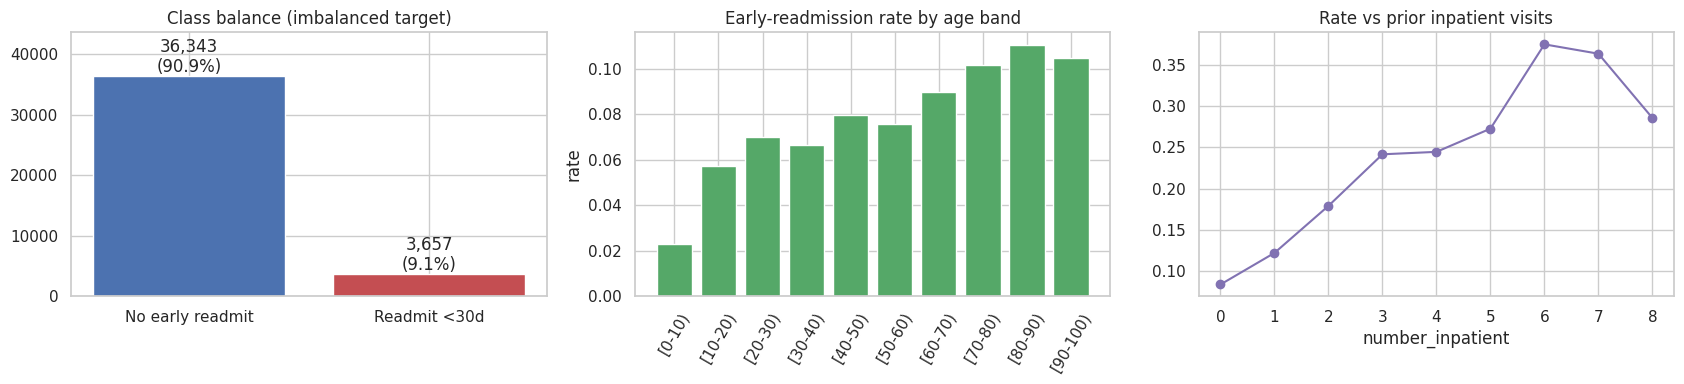

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cnt = df[TARGET].value_counts().sort_index()
ax[0].bar(['No early readmit', 'Readmit <30d'], cnt.values, color=['#4c72b0', '#c44e52'])
for i, v in enumerate(cnt.values): ax[0].text(i, v, f'{v:,}\n({v/len(df):.1%})', ha='center', va='bottom')
ax[0].set_title('Class balance (imbalanced target)'); ax[0].set_ylim(0, cnt.max() * 1.2)

rate = df.groupby('age')[TARGET].apply(lambda s: (s == '1').mean())
ax[1].bar(range(len(rate)), rate.values, color='#55a868')
ax[1].set_xticks(range(len(rate))); ax[1].set_xticklabels(rate.index, rotation=60)
ax[1].set_title('Early-readmission rate by age band'); ax[1].set_ylabel('rate')

g = df.groupby('number_inpatient')[TARGET].apply(lambda s: (s == '1').mean()).loc[:8]
ax[2].plot(g.index, g.values, marker='o', color='#8172b2')
ax[2].set_title('Rate vs prior inpatient visits'); ax[2].set_xlabel('number_inpatient')
plt.tight_layout(); save_show(fig, '01_eda_real')

## 10 · Why privacy matters here – quasi-identifier uniqueness
Even without names, a combination of attributes (age band, gender, race, insurance payer, admitting specialty, primary diagnosis) can single out a person. This is the classic *quasi-identifier* re-identification risk (k-anonymity). We measure how many real patients are **unique** on these six attributes – these are the records a naïve data release would expose.

Patients unique on the 6 quasi-identifiers (k = 1): 14.1%
Patients in groups smaller than 5 (k < 5):              30.4%


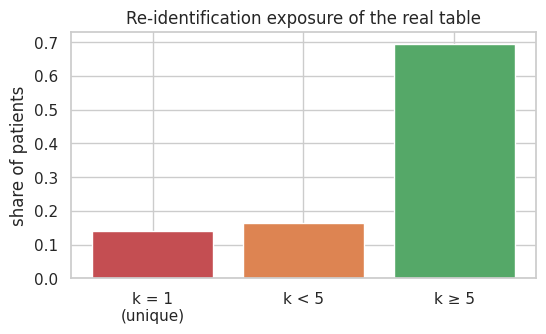

In [ ]:
QI = ['age', 'gender', 'race', 'payer_code', 'medical_specialty', 'diag_1']
k = df.groupby(QI)[TARGET].transform('size')
uniq_pct, k5_pct = (k == 1).mean(), (k < 5).mean()
print(f'Patients unique on the {len(QI)} quasi-identifiers (k = 1): {uniq_pct:.1%}')
print(f'Patients in groups smaller than 5 (k < 5):              {k5_pct:.1%}')
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(['k = 1\n(unique)', 'k < 5', 'k ≥ 5'], [uniq_pct, k5_pct - uniq_pct, 1 - k5_pct],
       color=['#c44e52', '#dd8452', '#55a868'])
ax.set_ylabel('share of patients'); ax.set_title('Re-identification exposure of the real table')
save_show(fig, '02_qi_uniqueness')

## 11 · Patient-level split and the tabular encoder
* Each row is a different patient (first-encounter rule), so a random split is already **patient-level** – no person appears in both train and test.
* The generators only ever see the **training split**. The **test split** is used twice: as the real hold-out for utility (TSTR) and as the *non-member* reference for privacy attacks.

**Encoding.** Mixed-type tables cannot be fed directly to a neural net:
* numeric counts → `log1p` → z-score (counts are heavy-tailed); decoded back with `expm1`, rounding and clipping to the observed range;
* categorical columns → one-hot; categories rarer than 0.5 % are merged into `__other__` (fewer dimensions and no tiny, identifying categories).

In [ ]:
class TabularEncoder:
    OTHER = '__other__'
    def __init__(self, num_cols, cat_cols, min_freq=0.005):
        self.num_cols, self.cat_cols, self.min_freq = list(num_cols), list(cat_cols), min_freq

    def fit(self, df):
        self.num_min = {c: int(df[c].min()) for c in self.num_cols}
        self.num_max = {c: int(df[c].max()) for c in self.num_cols}
        self.scaler = StandardScaler().fit(np.log1p(df[self.num_cols].values.astype(float)))
        self.cats, self.fallback = {}, {}
        for c in self.cat_cols:
            vc = df[c].astype(str).value_counts(normalize=True)
            keep = sorted(vc[vc >= self.min_freq].index.tolist())
            rare = bool((vc < self.min_freq).any())
            self.cats[c] = keep + ([self.OTHER] if rare else [])
            self.fallback[c] = self.OTHER if rare else vc.index[0]
        self.n_num, self.groups, start = len(self.num_cols), [], len(self.num_cols)
        for c in self.cat_cols:
            k = len(self.cats[c]); self.groups.append((c, start, start + k)); start += k
        self.dim = start
        return self

    def prepare(self, df):
        """Return the table in the model's label space (rare categories merged, numerics clipped)."""
        out = df[self.num_cols + self.cat_cols].copy()
        for c in self.cat_cols:
            out[c] = out[c].astype(str)
            out[c] = out[c].where(out[c].isin(self.cats[c]), self.fallback[c])
        for c in self.num_cols:
            out[c] = out[c].clip(self.num_min[c], self.num_max[c]).astype(int)
        return out.reset_index(drop=True)

    def transform(self, df):
        d = self.prepare(df)
        num = self.scaler.transform(np.log1p(d[self.num_cols].values.astype(float)))
        blocks = [num.astype(np.float32)]
        for c in self.cat_cols:
            idx = pd.Categorical(d[c], categories=self.cats[c]).codes
            oh = np.zeros((len(d), len(self.cats[c])), dtype=np.float32)
            oh[np.arange(len(d)), idx] = 1.0
            blocks.append(oh)
        return np.hstack(blocks)

    def inverse_transform(self, mat):
        mat = np.asarray(mat)
        z = self.scaler.inverse_transform(mat[:, :self.n_num])
        lo = np.log1p([self.num_min[c] for c in self.num_cols]); hi = np.log1p([self.num_max[c] for c in self.num_cols])
        num = np.rint(np.expm1(np.clip(z, lo, hi))).astype(int)
        out = pd.DataFrame(num, columns=self.num_cols)
        for c, s, e in self.groups:
            out[c] = np.array(self.cats[c])[mat[:, s:e].argmax(1)]
        return out[self.num_cols + self.cat_cols]

    def split_xy(self, X):
        """Feature matrix without the target block, and the 0/1 target."""
        s, e = [(s, e) for c, s, e in self.groups if c == TARGET][0]
        mask = np.ones(X.shape[1], bool); mask[s:e] = False
        return X[:, mask], X[:, s:e].argmax(1)

train_df, test_df = train_test_split(df, test_size=CFG['test_size'], stratify=df[TARGET], random_state=SEED)
enc = TabularEncoder(NUM_COLS, CAT_COLS, CFG['min_cat_freq']).fit(train_df)
real_train, real_test = enc.prepare(train_df), enc.prepare(test_df)     # "real" tables in model label space
X_train, X_test = enc.transform(real_train), enc.transform(real_test)
print(f'train {len(real_train):,} | test {len(real_test):,} | encoded width = {enc.dim} '
      f'({enc.n_num} numeric + {enc.dim - enc.n_num} one-hot)')

# sanity check: encode → decode must reproduce the table exactly
rt = enc.inverse_transform(X_train[:2000])
match = (rt.reset_index(drop=True) == real_train.iloc[:2000].reset_index(drop=True)).all(axis=1).mean()
print(f'Round-trip exactness (encode→decode): {match:.1%}')
assert match > 0.99, 'Encoder round-trip is broken'

train 32,000 | test 8,000 | encoded width = 155 (8 numeric + 147 one-hot)
Round-trip exactness (encode→decode): 100.0%


## 12 · Model definitions

### 12.1 Reconstruction loss (shared by AE and VAE)
Output = numeric block (regression) + one logit block per categorical column.
`loss = Σ MSE(numeric) + Σ CrossEntropy(each categorical group)` – the negative log-likelihood of a mixed Gaussian/categorical decoder.

### 12.2 Autoencoder (AE)
`input → 256 → 128 → latent(16) → 128 → 256 → output`. A deterministic AE has **no probabilistic prior**, so it cannot sample new data by itself. *Novelty #1:* after training we fit a **Gaussian Mixture Model on the latent codes** and decode samples from it.

### 12.3 Variational Autoencoder (VAE)
Encoder outputs `μ, log σ²`; reparameterisation `z = μ + σ·ε`; loss = reconstruction + **β·KL(q(z|x) ‖ N(0, I))**. We use **KL annealing** (β ramps linearly from 0 to its target over the first 30 % of epochs) to avoid *posterior collapse*. The β-VAE sweep later turns β into a privacy–utility dial.

### 12.4 WGAN-GP
Generator: noise(64) → residual MLP blocks with BatchNorm → raw outputs. Categorical blocks pass through **Gumbel-softmax (τ = 0.2)** so the critic sees near one-hot vectors (otherwise it can trivially separate soft vs. hard one-hots). Critic: MLP with LeakyReLU, trained with the **Wasserstein loss + gradient penalty (λ = 10)** and 5 critic steps per generator step – the standard recipe for stable GAN training (Gulrajani et al., 2017).

### 12.5 Residual-noise sampling
A Gaussian decoder has a variance; sampling only its mean makes numeric columns too "clean". After AE/VAE training we estimate the per-column reconstruction residual σ and add `N(0, σ²)` noise when generating numeric columns. Categorical columns are **sampled** from the softmax (not arg-maxed), which preserves category proportions.

In [ ]:
def recon_loss(out, x):
    n = enc.n_num
    mse = F.mse_loss(out[:, :n], x[:, :n], reduction='none').sum(1)
    ce = 0.0
    for _, s, e in enc.groups:
        ce = ce - (x[:, s:e] * F.log_softmax(out[:, s:e], dim=1)).sum(1)
    return (mse + ce).mean()

class AutoEncoder(nn.Module):
    def __init__(self, d_in, d_lat, h=(256, 128)):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, h[0]), nn.ReLU(), nn.Linear(h[0], h[1]), nn.ReLU(), nn.Linear(h[1], d_lat))
        self.dec = nn.Sequential(nn.Linear(d_lat, h[1]), nn.ReLU(), nn.Linear(h[1], h[0]), nn.ReLU(), nn.Linear(h[0], d_in))
    def forward(self, x):
        z = self.enc(x); return self.dec(z), z

class VAE(nn.Module):
    def __init__(self, d_in, d_lat, h=(256, 128)):
        super().__init__()
        self.trunk = nn.Sequential(nn.Linear(d_in, h[0]), nn.ReLU(), nn.Linear(h[0], h[1]), nn.ReLU())
        self.mu, self.logvar = nn.Linear(h[1], d_lat), nn.Linear(h[1], d_lat)
        self.dec = nn.Sequential(nn.Linear(d_lat, h[1]), nn.ReLU(), nn.Linear(h[1], h[0]), nn.ReLU(), nn.Linear(h[0], d_in))
    def encode(self, x):
        h = self.trunk(x); return self.mu(h), self.logvar(h)
    def forward(self, x):
        mu, lv = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
        return self.dec(z), mu, lv

class ResBlock(nn.Module):
    def __init__(self, h):
        super().__init__(); self.fc, self.bn = nn.Linear(h, h), nn.BatchNorm1d(h)
    def forward(self, x): return x + F.relu(self.bn(self.fc(x)))

class Generator(nn.Module):
    def __init__(self, z_dim, d_out, h=256, blocks=2):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(z_dim, h), nn.BatchNorm1d(h), nn.ReLU())
        self.blocks = nn.Sequential(*[ResBlock(h) for _ in range(blocks)])
        self.out = nn.Linear(h, d_out)
    def forward(self, z): return self.out(self.blocks(self.inp(z)))

class Critic(nn.Module):
    def __init__(self, d_in, h=(256, 128)):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, h[0]), nn.LeakyReLU(0.2), nn.Linear(h[0], h[1]), nn.LeakyReLU(0.2), nn.Linear(h[1], 1))
    def forward(self, x): return self.net(x)

def gan_activate(raw, tau=0.2, hard=False):
    parts = [raw[:, :enc.n_num]]
    for _, s, e in enc.groups:
        parts.append(F.gumbel_softmax(raw[:, s:e], tau=tau, hard=hard))
    return torch.cat(parts, 1)

def n_params(m): return sum(p.numel() for p in m.parameters())
_ae, _vae = AutoEncoder(enc.dim, CFG['latent_dim']), VAE(enc.dim, CFG['latent_dim'])
_g, _c = Generator(CFG['gan_z_dim'], enc.dim), Critic(enc.dim)
print(pd.DataFrame({'model': ['Autoencoder', 'VAE', 'WGAN-GP generator', 'WGAN-GP critic'],
                    'parameters': [n_params(_ae), n_params(_vae), n_params(_g), n_params(_c)]}).to_string(index=False))
del _ae, _vae, _g, _c

            model  parameters
      Autoencoder      149931
              VAE      151995
WGAN-GP generator      189595
   WGAN-GP critic       72961


## 13 · Training loops
Each loop returns its loss history so we can plot convergence. The GAN loop records the critic loss, generator loss and the **Wasserstein-distance estimate** (a useful training-progress signal – it should shrink and stabilise).

In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
def make_loader(X, bs): return DataLoader(TensorDataset(X), batch_size=bs, shuffle=True, drop_last=True)

def train_ae(model, X, epochs, lr, bs, desc='AE'):
    opt, loader, hist = torch.optim.Adam(model.parameters(), lr=lr), make_loader(X, bs), []
    model.train()
    for _ in tqdm(range(epochs), desc=desc, leave=False):
        tot = n = 0
        for (xb,) in loader:
            out, _ = model(xb); loss = recon_loss(out, xb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb); n += len(xb)
        hist.append(tot / n)
    return hist

def train_vae(model, X, epochs, lr, bs, beta, anneal_frac, desc='VAE'):
    opt, loader, hist = torch.optim.Adam(model.parameters(), lr=lr), make_loader(X, bs), []
    warm = max(1, int(anneal_frac * epochs)); model.train()
    for ep in tqdm(range(epochs), desc=desc, leave=False):
        b = beta * min(1.0, (ep + 1) / warm)
        tr = tk = n = 0
        for (xb,) in loader:
            out, mu, lv = model(xb)
            rec = recon_loss(out, xb)
            kl = (-0.5 * (1 + lv - mu.pow(2) - lv.exp()).sum(1)).mean()
            loss = rec + b * kl
            opt.zero_grad(); loss.backward(); opt.step()
            tr += rec.item() * len(xb); tk += kl.item() * len(xb); n += len(xb)
        hist.append((tr / n, tk / n))
    return hist

def gradient_penalty(D, real, fake):
    a = torch.rand(real.size(0), 1, device=real.device)
    inter = (a * real + (1 - a) * fake).requires_grad_(True)
    d = D(inter)
    g = torch.autograd.grad(d, inter, torch.ones_like(d), create_graph=True, retain_graph=True)[0]
    return ((g.norm(2, dim=1) - 1) ** 2).mean()

def train_wgan_gp(G, D, X, steps, bs, z_dim, n_critic, lr, gp_w, desc='WGAN-GP'):
    oG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9))
    oD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.9))
    hist = []; N = len(X); G.train(); D.train()
    for _ in tqdm(range(steps), desc=desc, leave=False):
        for _ in range(n_critic):
            real = X[torch.randint(0, N, (bs,), device=X.device)]
            with torch.no_grad():
                fake = gan_activate(G(torch.randn(bs, z_dim, device=X.device)))
            wd = D(real).mean() - D(fake).mean()
            loss_d = -wd + gp_w * gradient_penalty(D, real, fake)
            oD.zero_grad(); loss_d.backward(); oD.step()
        fake = gan_activate(G(torch.randn(bs, z_dim, device=X.device)))
        loss_g = -D(fake).mean()
        oG.zero_grad(); loss_g.backward(); oG.step()
        hist.append((loss_d.item(), loss_g.item(), wd.item()))
    return hist

## 14 · Generation helpers
`logits_to_matrix` converts decoder/generator outputs into a one-hot-encoded matrix (numeric + sampled categories), and `enc.inverse_transform` turns it back into a readable patient table.

In [ ]:
@torch.no_grad()
def logits_to_matrix(out, res_std=None):
    out = out.detach().cpu().float(); n = enc.n_num
    mat = torch.zeros_like(out)
    num = out[:, :n]
    if res_std is not None: num = num + torch.randn_like(num) * res_std.cpu()
    mat[:, :n] = num
    rows = torch.arange(len(out))
    for _, s, e in enc.groups:
        idx = torch.multinomial(F.softmax(out[:, s:e], dim=1), 1).squeeze(1)
        mat[rows, s + idx] = 1.0
    return mat.numpy()

@torch.no_grad()
def recon_residual_std(model, X, kind):
    model.eval(); Xs = X[:20000]
    out = model(Xs)[0] if kind == 'ae' else model.dec(model.encode(Xs)[0])
    return (out[:, :enc.n_num] - Xs[:, :enc.n_num]).std(0)

@torch.no_grad()
def generate_ae(model, gmm, n, res_std):
    model.eval(); z, _ = gmm.sample(n)
    return enc.inverse_transform(logits_to_matrix(model.dec(torch.tensor(z, dtype=torch.float32, device=DEVICE)), res_std))

@torch.no_grad()
def generate_vae(model, n, res_std, d_lat):
    model.eval()
    return enc.inverse_transform(logits_to_matrix(model.dec(torch.randn(n, d_lat, device=DEVICE)), res_std))

@torch.no_grad()
def generate_gan(G, n, z_dim, batch=4096):
    G.eval(); mats = []
    for i in range(0, n, batch):
        m = min(batch, n - i)
        mats.append(logits_to_matrix(G(torch.randn(m, z_dim, device=DEVICE))))
    return enc.inverse_transform(np.vstack(mats))

def marginal_baseline(real, n, seed=SEED):
    rng = np.random.default_rng(seed)
    return pd.DataFrame({c: rng.choice(real[c].values, size=n, replace=True) for c in real.columns})

## 15 · Train the three generators
Training times are recorded because **compute cost is part of the comparison** (AE/VAE train in seconds, the GAN needs many more updates).

In [ ]:
N_SYN = len(real_train)                        # synthetic table has the same size as the training table
train_time, hist = {}, {}

t0 = time.time()
ae = AutoEncoder(enc.dim, CFG['latent_dim']).to(DEVICE)
hist['AE+GMM'] = train_ae(ae, X_train_t, CFG['ae_epochs'], CFG['lr'], CFG['batch_size'], 'Autoencoder')
ae.eval()
with torch.no_grad(): Z_ae = ae.enc(X_train_t).cpu().numpy()
gmm = GaussianMixture(CFG['gmm_components'], covariance_type='full', random_state=SEED).fit(Z_ae)
ae_res = recon_residual_std(ae, X_train_t, 'ae')
train_time['AE+GMM'] = time.time() - t0

t0 = time.time()
vae = VAE(enc.dim, CFG['latent_dim']).to(DEVICE)
hist['VAE'] = train_vae(vae, X_train_t, CFG['vae_epochs'], CFG['lr'], CFG['batch_size'],
                        CFG['vae_beta'], CFG['kl_anneal_frac'], 'VAE')
vae_res = recon_residual_std(vae, X_train_t, 'vae')
train_time['VAE'] = time.time() - t0

t0 = time.time()
G, D = Generator(CFG['gan_z_dim'], enc.dim).to(DEVICE), Critic(enc.dim).to(DEVICE)
hist['WGAN-GP'] = train_wgan_gp(G, D, X_train_t, CFG['gan_steps'], CFG['batch_size'], CFG['gan_z_dim'],
                                CFG['gan_n_critic'], CFG['gan_lr'], CFG['gan_gp'], 'WGAN-GP')
train_time['WGAN-GP'] = time.time() - t0
print({k: f'{v:.0f}s' for k, v in train_time.items()})

Autoencoder:   0%|          | 0/40 [00:00<?, ?it/s]

VAE:   0%|          | 0/40 [00:00<?, ?it/s]

WGAN-GP:   0%|          | 0/3000 [00:00<?, ?it/s]

{'AE+GMM': '53s', 'VAE': '28s', 'WGAN-GP': '132s'}


### 15.1 Convergence curves
* **AE** – reconstruction loss should fall and flatten.
* **VAE** – reconstruction falls while KL rises as β is annealed in; a KL stuck at ~0 would signal posterior collapse.
* **WGAN-GP** – the Wasserstein estimate should shrink towards a small stable value.

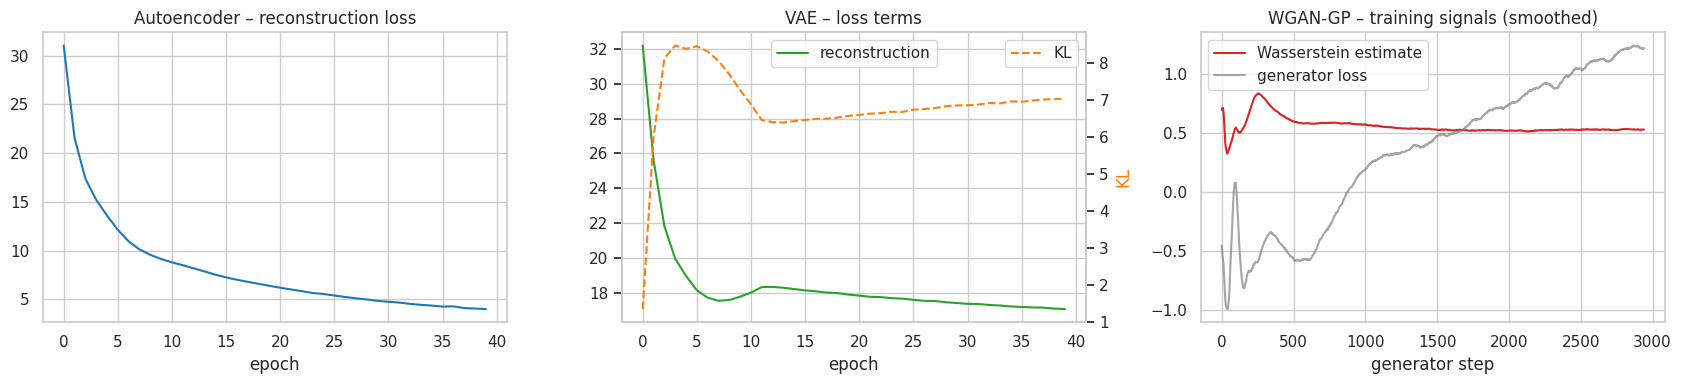

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(hist['AE+GMM'], color=PALETTE['AE+GMM']); ax[0].set_title('Autoencoder – reconstruction loss'); ax[0].set_xlabel('epoch')
rec, kl = zip(*hist['VAE'])
ax[1].plot(rec, color=PALETTE['VAE'], label='reconstruction'); ax[1].set_xlabel('epoch'); ax[1].set_title('VAE – loss terms')
ax1b = ax[1].twinx(); ax1b.plot(kl, color='#ff7f0e', ls='--', label='KL'); ax1b.set_ylabel('KL', color='#ff7f0e'); ax1b.grid(False)
ax[1].legend(loc='upper center'); ax1b.legend(loc='upper right')
gd, gg, gw = zip(*hist['WGAN-GP'])
def sm(a):
    a = np.asarray(a); w = max(1, len(a) // 50)
    return np.convolve(a, np.ones(w) / w, mode='valid')
ax[2].plot(sm(gw), color=PALETTE['WGAN-GP'], label='Wasserstein estimate'); ax[2].plot(sm(gg), color='#7f7f7f', alpha=.7, label='generator loss')
ax[2].set_title('WGAN-GP – training signals (smoothed)'); ax[2].set_xlabel('generator step'); ax[2].legend()
plt.tight_layout(); save_show(fig, '03_training_curves')

## 16 · Generate synthetic patient tables
Each model produces as many synthetic patients as there are training patients. The **independent-marginals baseline** is added as a floor: it matches every single-column distribution perfectly by construction but destroys all relationships – so any metric worth trusting must *punish* it.

In [ ]:
synth = {}
synth['Marginals'] = marginal_baseline(real_train, N_SYN)
synth['AE+GMM'] = generate_ae(ae, gmm, N_SYN, ae_res)
synth['VAE'] = generate_vae(vae, N_SYN, vae_res, CFG['latent_dim'])
synth['WGAN-GP'] = generate_gan(G, N_SYN, CFG['gan_z_dim'])
for k, v in synth.items():
    v.to_csv(OUT / f'synthetic_{k.replace("+", "_").replace("-", "_")}.csv', index=False)
print({k: v.shape for k, v in synth.items()})
print('\nSample of synthetic VAE records:')
display(synth['VAE'].head(5).T)

{'Marginals': (32000, 32), 'AE+GMM': (32000, 32), 'VAE': (32000, 32), 'WGAN-GP': (32000, 32)}

Sample of synthetic VAE records:


,0,1,2,3,4
time_in_hospital,1,1,3,5,5
num_lab_procedures,22,31,2,58,37
num_procedures,0,1,4,0,1
num_medications,16,8,14,22,22
number_outpatient,0,0,0,1,0
number_emergency,0,0,0,0,0
number_inpatient,1,0,0,2,0
number_diagnoses,8,6,6,10,10
race,Caucasian,AfricanAmerican,AfricanAmerican,Caucasian,Caucasian
gender,Male,Female,Female,Female,Female


## 17 · Pillar 1 – Statistical fidelity (single columns)
* **Numeric columns:** `1 − KS` where KS is the two-sample Kolmogorov–Smirnov statistic (max gap between the two CDFs).
* **Categorical columns:** `1 − TVD` where TVD is the total-variation distance between category proportions.

Both scores lie in [0, 1]; **1 = identical distribution**.

Mean column-shape score:
Marginals    0.997
AE+GMM       0.940
VAE          0.972
WGAN-GP      0.980


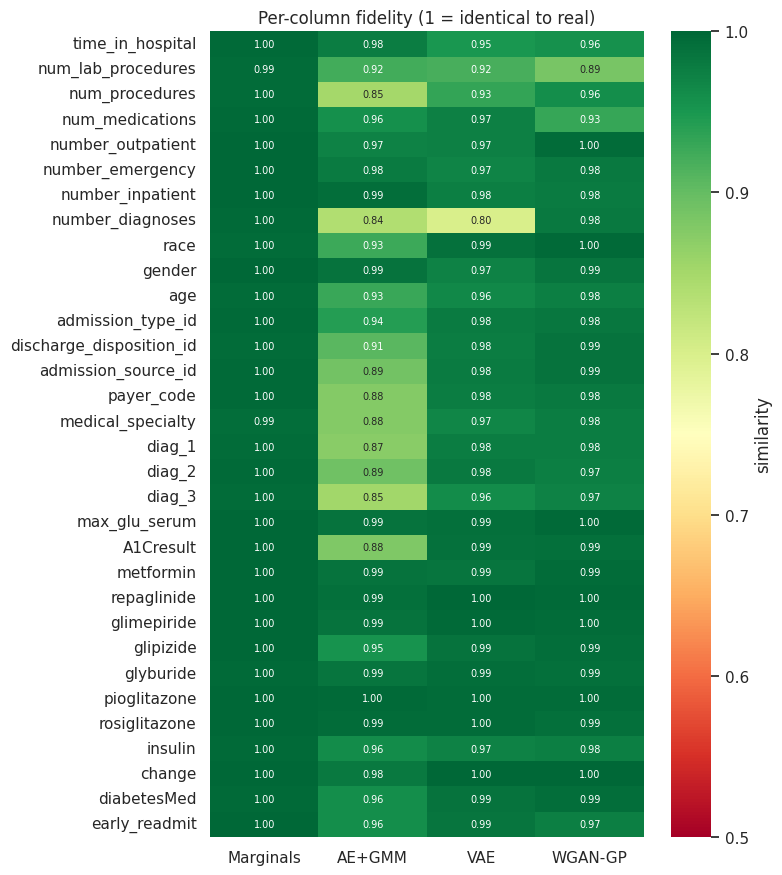

In [ ]:
def tvd(a, b):
    pa, pb = a.value_counts(normalize=True), b.value_counts(normalize=True)
    idx = pa.index.union(pb.index)
    return 0.5 * np.abs(pa.reindex(idx, fill_value=0) - pb.reindex(idx, fill_value=0)).sum()

def column_scores(real, syn):
    rows = [(c, 'numeric', 1 - stats.ks_2samp(real[c], syn[c]).statistic) for c in enc.num_cols]
    rows += [(c, 'categorical', 1 - tvd(real[c], syn[c])) for c in enc.cat_cols]
    return pd.DataFrame(rows, columns=['column', 'type', 'score'])

col_scores = {k: column_scores(real_train, v) for k, v in synth.items()}
fid_tbl = pd.DataFrame({k: v.set_index('column')['score'] for k, v in col_scores.items()})
fid_tbl.insert(0, 'type', col_scores['VAE'].set_index('column')['type'])
print('Mean column-shape score:')
print(fid_tbl[SOURCES].mean().round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 0.28 * len(fid_tbl) + 1.5))
sns.heatmap(fid_tbl[SOURCES], annot=True, fmt='.2f', cmap='RdYlGn', vmin=0.5, vmax=1, cbar_kws={'label': 'similarity'}, ax=ax, annot_kws={'size': 7})
ax.set_title('Per-column fidelity (1 = identical to real)'); ax.set_ylabel('')
save_show(fig, '04_column_fidelity_heatmap')

### 17.1 Visual check – numeric columns
Filled grey = real distribution; coloured lines = each generator (probability mass per count value).

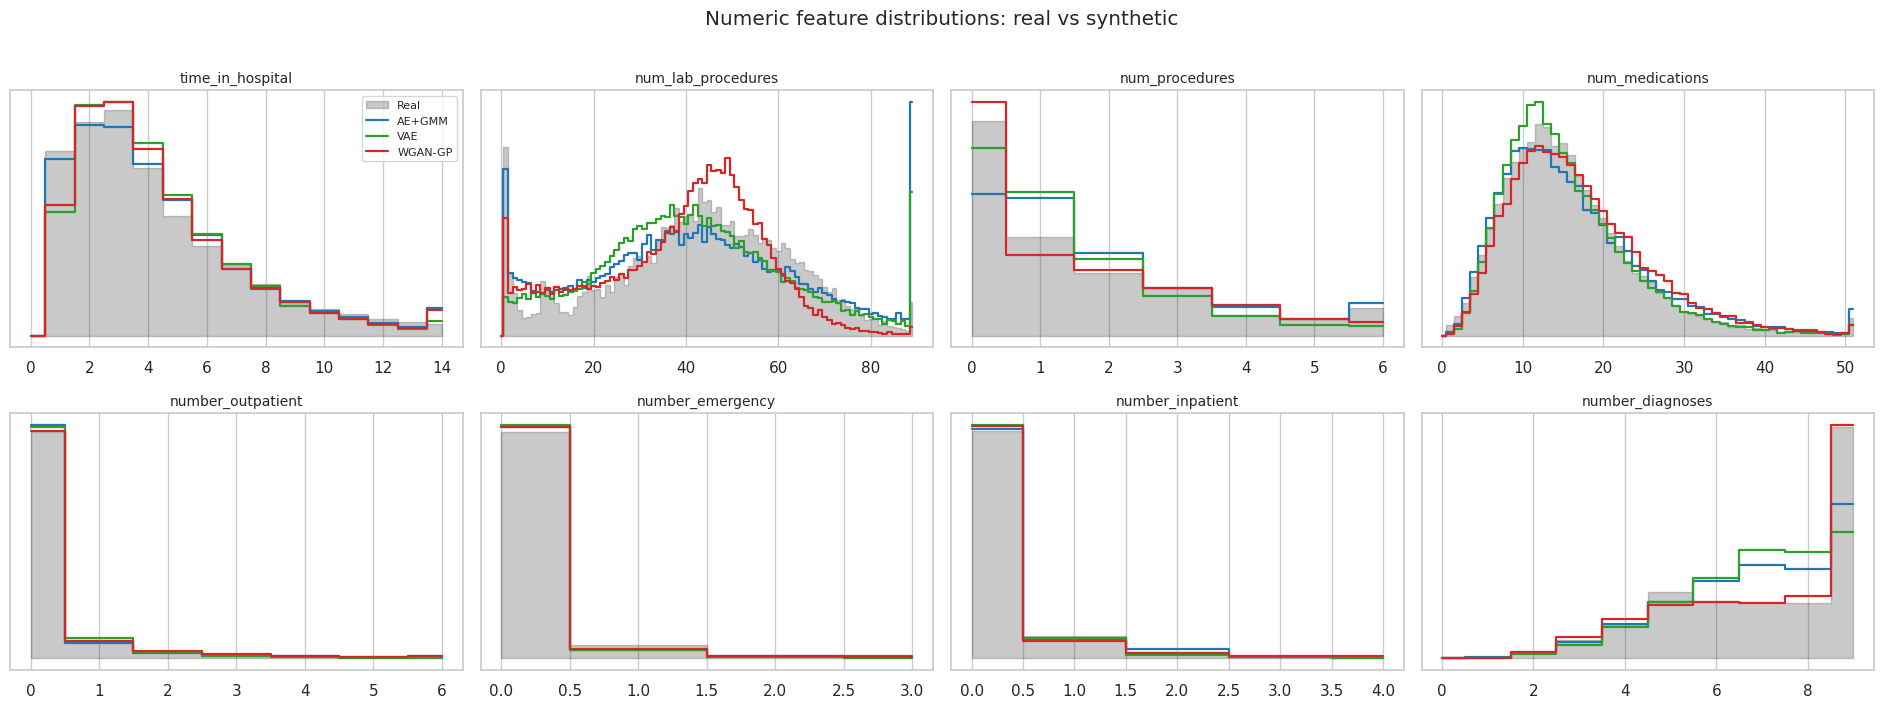

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(19, 7))
for ax, c in zip(axes.ravel(), enc.num_cols):
    hi = int(np.percentile(real_train[c], 99.5)); bins = np.arange(0, hi + 2)
    r = np.histogram(real_train[c].clip(upper=hi), bins=bins, density=True)[0]
    ax.fill_between(bins[:-1], r, step='mid', color=PALETTE['Real'], alpha=.25, label='Real')
    for m in MODELS:
        h = np.histogram(synth[m][c].clip(upper=hi), bins=bins, density=True)[0]
        ax.step(bins[:-1], h, where='mid', color=PALETTE[m], lw=1.6, label=m)
    ax.set_title(c, fontsize=10); ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
plt.suptitle('Numeric feature distributions: real vs synthetic', y=1.01); plt.tight_layout(); save_show(fig, '05_numeric_distributions')

### 17.2 Visual check – categorical columns
Grouped bars show the proportion of each category. A model that "mode-collapses" (e.g. the GAN) tends to over-produce the commonest category.

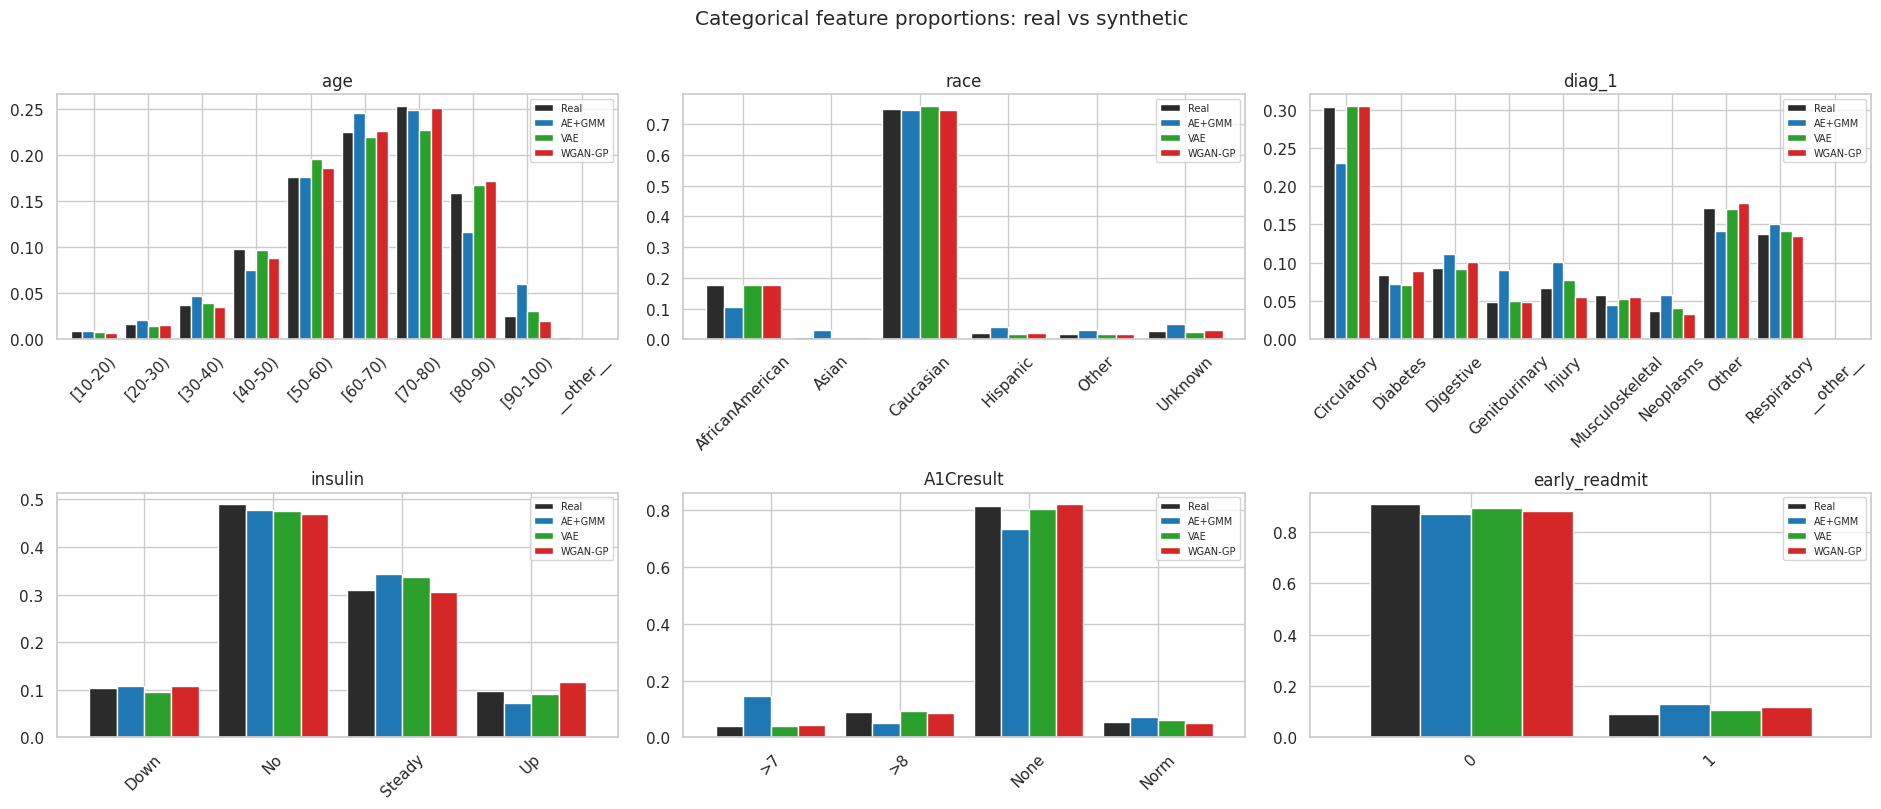

In [ ]:
show_cols = ['age', 'race', 'diag_1', 'insulin', 'A1Cresult', TARGET]
show_cols = [c for c in show_cols if c in enc.cat_cols]
fig, axes = plt.subplots(2, 3, figsize=(19, 8))
for ax, c in zip(axes.ravel(), show_cols):
    props = pd.DataFrame({'Real': real_train[c].value_counts(normalize=True),
                          **{m: synth[m][c].value_counts(normalize=True) for m in MODELS}}).fillna(0).sort_index()
    props.plot.bar(ax=ax, color=[PALETTE[x] for x in props.columns], width=.85)
    ax.set_title(c); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=45); ax.legend(fontsize=7)
for ax in axes.ravel()[len(show_cols):]: ax.axis('off')
plt.suptitle('Categorical feature proportions: real vs synthetic', y=1.01); plt.tight_layout(); save_show(fig, '06_categorical_distributions')

## 18 · Pillar 1b – Do the *relationships between features* survive? (novelty #3)
Matching every histogram is easy (the baseline does it perfectly). What matters clinically is that **dependencies** such as *age ↔ medications* or *prior visits ↔ readmission* are retained.
We build an **association matrix** over all column pairs using the right measure for each type:

| Pair | Measure | Range |
|---|---|---|
| categorical – categorical | bias-corrected **Cramér's V** | 0–1 |
| categorical – numeric | **correlation ratio η** | 0–1 |
| numeric – numeric | **|Pearson r|** on log-counts | 0–1 |

**Relationship score.** Most column pairs are essentially unrelated, and averaging over all of them would hide failures. So we score only the **meaningful dependencies** (pairs whose real association is ≥ 0.10): `score = 1 − mean|A_real − A_syn| ÷ mean(A_real)` on those pairs, clipped to [0, 1] – i.e. *the share of real dependency strength that is reproduced*. A generator that ignores relationships (the independent-marginals baseline) scores near 0.

In [ ]:
def cramers_v(x, y):
    kx, ky = x.max() + 1, y.max() + 1
    if kx < 2 or ky < 2: return 0.0
    ct = np.bincount(x * ky + y, minlength=kx * ky).reshape(kx, ky).astype(float)
    n = ct.sum(); exp = ct.sum(1, keepdims=True) @ ct.sum(0, keepdims=True) / n
    chi2 = ((ct - exp) ** 2 / np.where(exp == 0, 1, exp)).sum()
    phi2 = max(0.0, chi2 / n - (kx - 1) * (ky - 1) / (n - 1))
    kxc, kyc = kx - (kx - 1) ** 2 / (n - 1), ky - (ky - 1) ** 2 / (n - 1)
    d = min(kxc - 1, kyc - 1)
    return float(np.sqrt(phi2 / d)) if d > 0 else 0.0

def corr_ratio(codes, vals):
    vals = vals.astype(float); tot = ((vals - vals.mean()) ** 2).sum()
    if tot == 0: return 0.0
    k = codes.max() + 1
    cnt = np.bincount(codes, minlength=k); sm = np.bincount(codes, weights=vals, minlength=k)
    means = np.divide(sm, cnt, out=np.zeros(k), where=cnt > 0)
    return float(np.sqrt((cnt * (means - vals.mean()) ** 2).sum() / tot))

def association_matrix(d, n=None, seed=0):
    if n and len(d) > n: d = d.sample(n, random_state=seed)
    cols = enc.num_cols + enc.cat_cols
    codes = {c: pd.factorize(d[c])[0] for c in enc.cat_cols}
    vals = {c: np.log1p(d[c].values.astype(float)) for c in enc.num_cols}
    M = np.eye(len(cols))
    with np.errstate(all='ignore'):
        for i, a in enumerate(cols):
            for j in range(i + 1, len(cols)):
                b = cols[j]
                if a in vals and b in vals: v = abs(np.corrcoef(vals[a], vals[b])[0, 1])
                elif a in vals: v = corr_ratio(codes[b], vals[a])
                elif b in vals: v = corr_ratio(codes[a], vals[b])
                else: v = cramers_v(codes[a], codes[b])
                M[i, j] = M[j, i] = 0.0 if np.isnan(v) else v
    return pd.DataFrame(M, index=cols, columns=cols)

A = {'Real': association_matrix(real_train, CFG['assoc_n'])}
for k, v in synth.items(): A[k] = association_matrix(v, CFG['assoc_n'])
iu = np.triu_indices(len(A['Real']), 1)

def relationship_score(Ar, As, thr=0.10):
    r, s = Ar.values[iu], As.values[iu]
    mask = r >= thr
    if mask.sum() < 5: mask = r >= np.sort(r)[-5]           # fall back to the 5 strongest real pairs
    return float(max(0.0, 1 - np.abs(r[mask] - s[mask]).mean() / r[mask].mean())), int(mask.sum())

assoc_score, n_meaningful = {}, None
for k in SOURCES: assoc_score[k], n_meaningful = relationship_score(A['Real'], A[k])
all_pairs_mae = {k: np.abs(A['Real'].values[iu] - A[k].values[iu]).mean() for k in SOURCES}
print(f'Relationship-preservation score (on {n_meaningful} meaningful real dependencies):')
print(pd.DataFrame({'score': assoc_score, 'all-pairs MAE': all_pairs_mae}).round(3).to_string())

Relationship-preservation score (on 114 meaningful real dependencies):
           score  all-pairs MAE
Marginals  0.061          0.067
AE+GMM     0.809          0.026
VAE        0.834          0.017
WGAN-GP    0.895          0.015


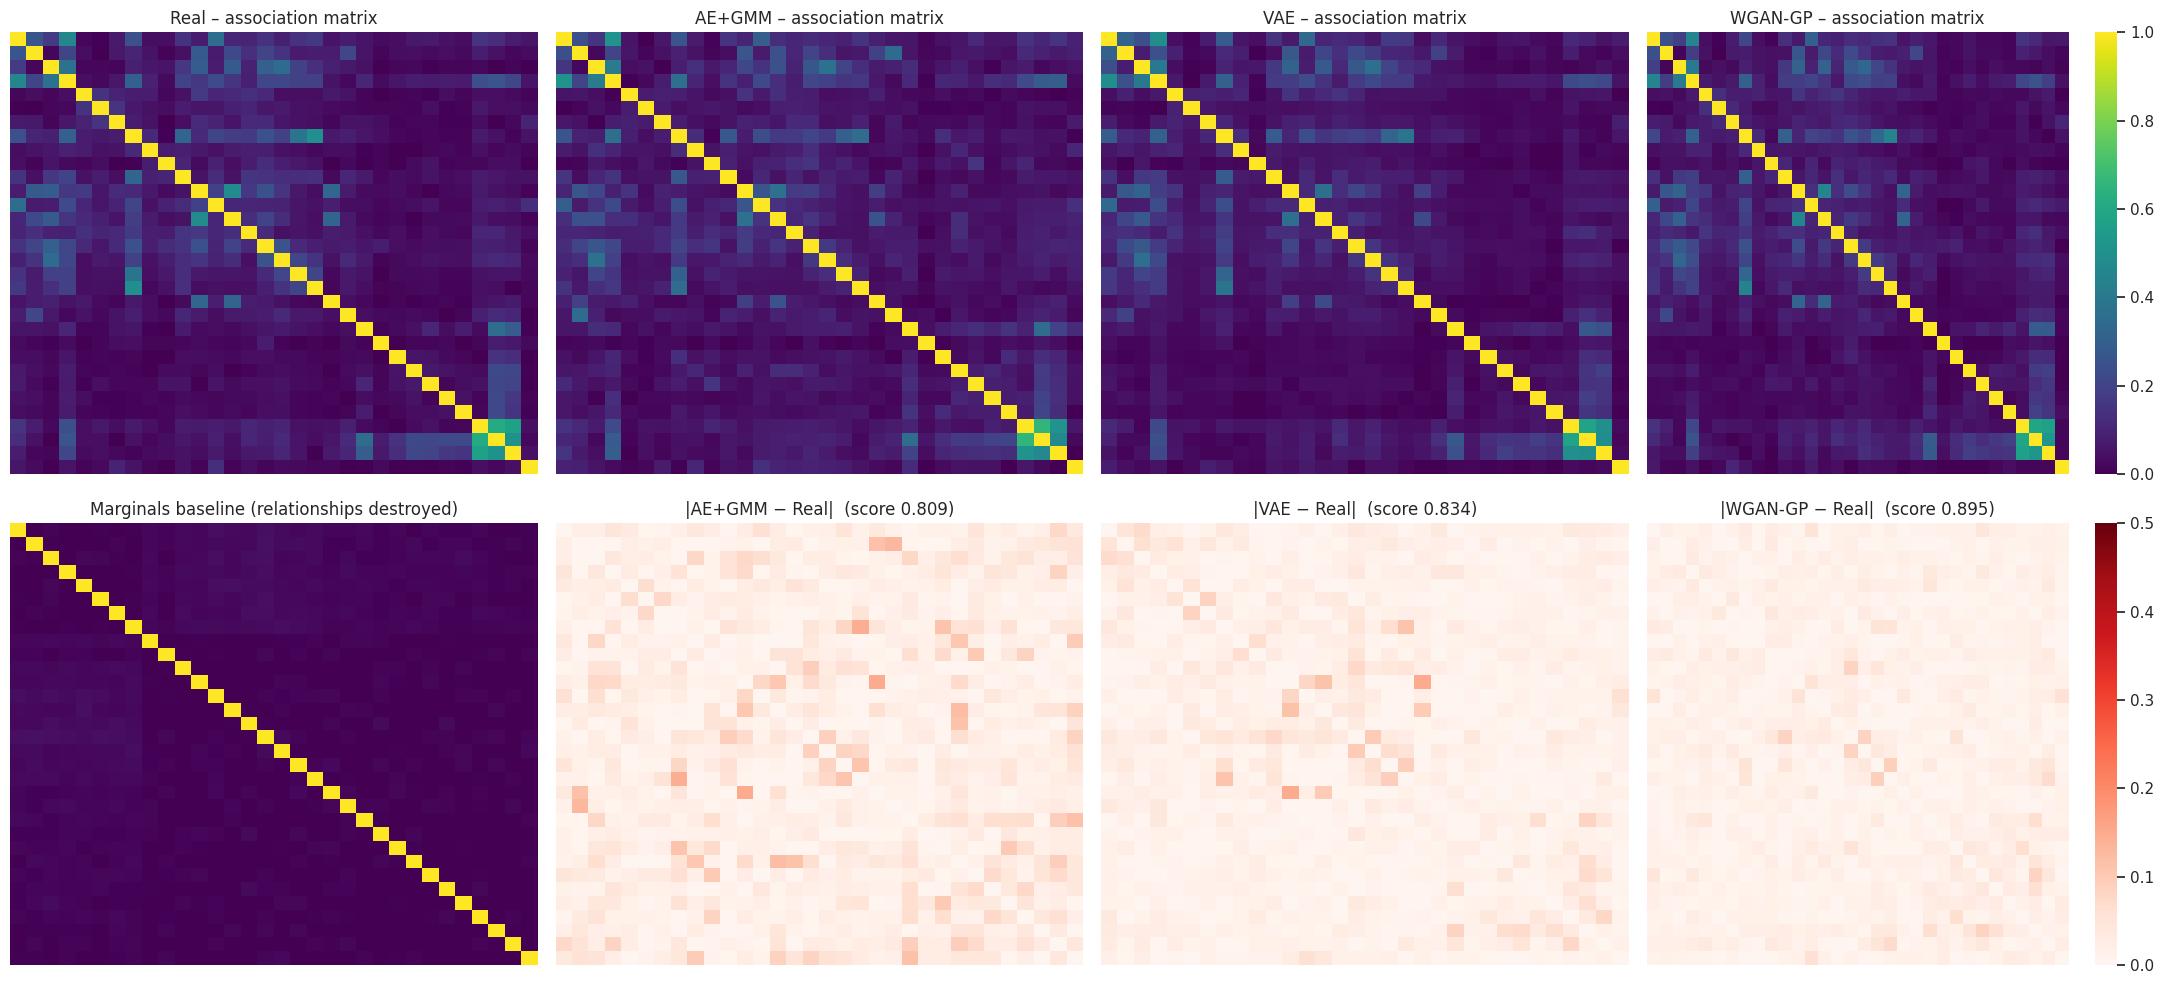


Ten strongest real relationships and how each generator preserves them:


,Real,Marginals,AE+GMM,VAE,WGAN-GP
pair,,,,,
insulin ↔ change,0.61,0.00,0.65,0.58,0.59
insulin ↔ diabetesMed,0.57,0.01,0.51,0.50,0.56
change ↔ diabetesMed,0.51,0.01,0.47,0.49,0.52
number_diagnoses ↔ diag_3,0.50,0.02,0.35,0.39,0.45
admission_type_id ↔ admission_source_id,0.47,0.00,0.37,0.36,0.45
time_in_hospital ↔ num_medications,0.46,0.00,0.51,0.49,0.45
number_diagnoses ↔ diag_2,0.38,0.03,0.30,0.32,0.33
num_procedures ↔ num_medications,0.37,0.00,0.41,0.40,0.41
metformin ↔ change,0.35,0.00,0.35,0.27,0.29


In [ ]:
order = ['Real', 'AE+GMM', 'VAE', 'WGAN-GP']
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, k in zip(axes[0], order):
    sns.heatmap(A[k], ax=ax, cmap='viridis', vmin=0, vmax=1, xticklabels=False, yticklabels=False, cbar=(k == 'WGAN-GP'))
    ax.set_title(f'{k} – association matrix')
sns.heatmap(A['Marginals'], ax=axes[1, 0], cmap='viridis', vmin=0, vmax=1, xticklabels=False, yticklabels=False, cbar=False)
axes[1, 0].set_title('Marginals baseline (relationships destroyed)')
for ax, k in zip(axes[1, 1:], MODELS):
    sns.heatmap((A[k] - A['Real']).abs(), ax=ax, cmap='Reds', vmin=0, vmax=.5, xticklabels=False, yticklabels=False, cbar=(k == 'WGAN-GP'))
    ax.set_title(f'|{k} − Real|  (score {assoc_score[k]:.3f})')
plt.tight_layout(); save_show(fig, '07_association_matrices')

# the strongest real relationships – are they preserved?
pairs = [(A['Real'].index[i], A['Real'].columns[j], A['Real'].values[i, j]) for i, j in zip(*iu)]
top = sorted(pairs, key=lambda t: -t[2])[:10]
top_tbl = pd.DataFrame([{'pair': f'{a} ↔ {b}', 'Real': r, **{m: A[m].loc[a, b] for m in SOURCES}} for a, b, r in top]).set_index('pair')
print('\nTen strongest real relationships and how each generator preserves them:'); display(top_tbl.round(2))

## 19 · Pillar 2 – Utility: Train on Synthetic, Test on Real (TSTR)
The practical question: **if a researcher only has the synthetic table, can they still build a useful early-readmission model?**
* **TRTR** = train on *real* training data → test on real hold-out (the upper bound).
* **TSTR** = train on *synthetic* data → test on the **same real hold-out**.
* Three different classifiers (Logistic Regression, Random Forest, Histogram Gradient Boosting) so the conclusion does not hinge on one algorithm. Class imbalance is handled with balanced sample weights.
* Metrics: **ROC-AUC**, **PR-AUC** (more informative for the rare positive class) and F1.
* **Skill retention** = `(AUC_TSTR − 0.5) / (AUC_TRTR − 0.5)` – the share of the real model's *above-chance* skill that survives. Raw AUC ratios flatter useless models (a random model already scores 0.5).

Readmission within 30 days is a genuinely hard task (published AUCs are modest, roughly 0.6–0.7), so the *relative* comparison is what counts.

In [ ]:
CLASSIFIERS = {
    'LogReg':     lambda: LogisticRegression(max_iter=500),
    'RandForest': lambda: RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    'HistGB':     lambda: HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, random_state=SEED),
}
Xte_f, yte = enc.split_xy(X_test)

def fit_eval(Xtr, ytr, which=None):
    res = {}
    for name, mk in CLASSIFIERS.items():
        if which and name not in which: continue
        if len(np.unique(ytr)) < 2:
            res[name] = dict(auc=np.nan, ap=np.nan, f1=np.nan, proba=np.full(len(yte), .5)); continue
        clf = mk(); clf.fit(Xtr, ytr, sample_weight=compute_sample_weight('balanced', ytr))
        p = clf.predict_proba(Xte_f)[:, 1]
        res[name] = dict(auc=roc_auc_score(yte, p), ap=average_precision_score(yte, p), f1=f1_score(yte, p > .5), proba=p)
    return res

Xtr_f, ytr = enc.split_xy(X_train)
util = {'Real (TRTR)': fit_eval(Xtr_f, ytr)}
Xsyn_enc = {}
for k, v in synth.items():
    Xsyn_enc[k] = enc.transform(v)
    util[k] = fit_eval(*enc.split_xy(Xsyn_enc[k]))

rows = [dict(source=s, classifier=c, ROC_AUC=r['auc'], PR_AUC=r['ap'], F1=r['f1']) for s, d in util.items() for c, r in d.items()]
util_df = pd.DataFrame(rows)
print('Positive rate in real hold-out:', f'{yte.mean():.3f}  (random-model PR-AUC ≈ this value)\n')
display(util_df.pivot(index='source', columns='classifier', values='ROC_AUC').loc[list(util.keys())].round(3))

Positive rate in real hold-out: 0.091  (random-model PR-AUC ≈ this value)



classifier,HistGB,LogReg,RandForest
source,,,
Real (TRTR),0.641,0.641,0.645
Marginals,0.494,0.510,0.494
AE+GMM,0.578,0.585,0.574
VAE,0.607,0.611,0.606
WGAN-GP,0.607,0.617,0.608


Skill retention (1.0 = synthetic data is as useful as real data):


,LogReg,RandForest,HistGB,mean
Marginals,0.074,0.000,0.000,0.025
AE+GMM,0.603,0.510,0.554,0.555
VAE,0.787,0.728,0.758,0.758
WGAN-GP,0.826,0.742,0.760,0.776


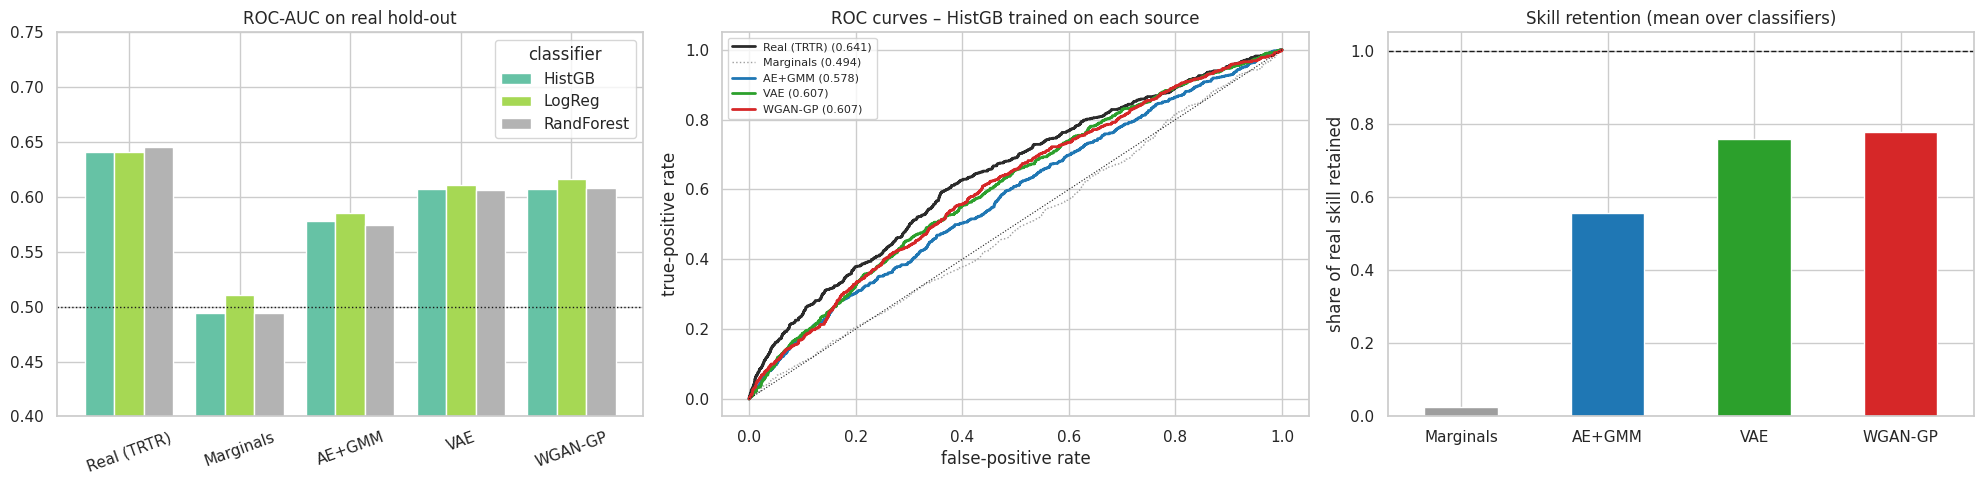

In [ ]:
trtr_auc = {c: util['Real (TRTR)'][c]['auc'] for c in CLASSIFIERS}
SKILL_FLOOR = 0.02                                   # avoids dividing by ~0 if the real model has almost no skill
denom = {c: max(trtr_auc[c] - .5, SKILL_FLOOR) for c in CLASSIFIERS}
if max(trtr_auc.values()) - .5 < 0.03:
    print('WARNING: the real-data model barely beats chance - increase max_rows / epochs before trusting utility ratios.')
skill = pd.DataFrame({k: {c: min(1.5, max(0.0, util[k][c]['auc'] - .5) / denom[c]) for c in CLASSIFIERS} for k in SOURCES}).T
skill['mean'] = skill.mean(1)
print('Skill retention (1.0 = synthetic data is as useful as real data):'); display(skill.round(3))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
order = ['Real (TRTR)'] + SOURCES
pv = util_df.pivot(index='source', columns='classifier', values='ROC_AUC').loc[order]
pv.plot.bar(ax=ax[0], width=.8, colormap='Set2'); ax[0].axhline(.5, color='k', ls=':', lw=1)
ax[0].set_ylim(.4, max(.75, pv.max().max() + .03)); ax[0].set_title('ROC-AUC on real hold-out'); ax[0].set_xlabel(''); ax[0].tick_params(axis='x', rotation=20)
for k in order:
    key = 'Real' if k.startswith('Real') else k
    fpr, tpr, _ = roc_curve(yte, util[k]['HistGB']['proba'])
    ax[1].plot(fpr, tpr, color=PALETTE[key], lw=2 if k != 'Marginals' else 1, ls='-' if k != 'Marginals' else ':', label=f"{k} ({util[k]['HistGB']['auc']:.3f})")
ax[1].plot([0, 1], [0, 1], 'k:', lw=.8); ax[1].set_title('ROC curves – HistGB trained on each source'); ax[1].legend(fontsize=8)
ax[1].set_xlabel('false-positive rate'); ax[1].set_ylabel('true-positive rate')
skill.loc[SOURCES, 'mean'].plot.bar(ax=ax[2], color=[PALETTE[s] for s in SOURCES]); ax[2].axhline(1, color='k', ls='--', lw=1)
ax[2].set_title('Skill retention (mean over classifiers)'); ax[2].set_ylabel('share of real skill retained'); ax[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); save_show(fig, '08_utility_tstr')

## 20 · Pillar 3 – Privacy audit (novelty #4 and #5)
Synthetic ≠ automatically private: a generator can **memorise** training patients and print them back. We audit four empirical signals (these are *audits*, not a formal differential-privacy guarantee):

1. **Exact-match rate** – share of synthetic rows that are identical to a real training row.
2. **Distance to Closest Record (DCR)** – for each synthetic record, the distance to its nearest *training* patient. Memorisation shows up as many near-zero distances. We compare against the DCR of **real hold-out patients** (who were never in training) – the natural "how close is a fresh real person" baseline. *Leak rate* = share of synthetic records closer to a training patient than the 5th percentile of that baseline (5 % is expected by chance, so ≈5 % means no leakage).
3. **Quasi-identifier hit rate** – share of records whose (age, gender, race, payer, specialty, diagnosis) combination matches a *unique* real training patient.
4. **Membership-inference attack (MIA)** – an attacker who has the synthetic table guesses "this person was in the training set" when a person's nearest synthetic record is unusually close. **AUC = 0.5 means the attacker is guessing (private); AUC → 1.0 means training membership is exposed** (Shokri et al., 2017).

**Audit calibration (novelty #5).** To prove the audit works we also run two controls: a *memorising generator* (a copy of training rows – must be flagged) and a *fresh-real generator* (real hold-out patients – must look clean).

In [ ]:
def exact_match_rate(real, syn):
    hr = set(pd.util.hash_pandas_object(real, index=False))
    return float(pd.util.hash_pandas_object(syn, index=False).isin(hr).mean())

def qi_hit_rate(probe, real):
    cnt = real.groupby(QI).size().rename('k').reset_index()
    uniq = cnt[cnt['k'] == 1][QI].assign(_hit=1)
    return float(probe[QI].merge(uniq, on=QI, how='left')['_hit'].notna().mean())

def privacy_audit(Xtr, Xhold, Xsyn, n, seed=SEED):
    rng = np.random.default_rng(seed)
    pick = lambda M: M[rng.choice(len(M), min(n, len(M)), replace=False)]
    mem, hold, syn_probe = pick(Xtr), pick(Xhold), pick(Xsyn)
    nn_syn = NearestNeighbors(n_neighbors=1).fit(Xsyn)
    d_mem, d_non = nn_syn.kneighbors(mem)[0][:, 0], nn_syn.kneighbors(hold)[0][:, 0]
    mia_auc = roc_auc_score(np.r_[np.ones(len(d_mem)), np.zeros(len(d_non))], -np.r_[d_mem, d_non])
    nn_tr = NearestNeighbors(n_neighbors=1).fit(Xtr)
    dcr_syn, dcr_hold = nn_tr.kneighbors(syn_probe)[0][:, 0], nn_tr.kneighbors(hold)[0][:, 0]
    thr = np.percentile(dcr_hold, 5)
    return dict(mia_auc=mia_auc, leak_rate=float((dcr_syn < thr).mean()),
                dcr_syn_median=float(np.median(dcr_syn)), dcr_hold_median=float(np.median(dcr_hold)),
                dcr_syn=dcr_syn, dcr_hold=dcr_hold)

priv = {}
for k, v in synth.items():
    priv[k] = privacy_audit(X_train, X_test, Xsyn_enc[k], CFG['privacy_n'])
    priv[k]['exact_match'] = exact_match_rate(real_train, v)
    priv[k]['qi_hit'] = qi_hit_rate(v, real_train)
    priv[k]['unique_rows'] = float(v.drop_duplicates().shape[0] / len(v))

# calibration controls
rng = np.random.default_rng(SEED)
copy_idx = rng.permutation(len(real_train))[:N_SYN]          # a generator that simply prints the training set
ctrl_copy = real_train.iloc[copy_idx].reset_index(drop=True)
half = len(real_test) // 2
ctrl_fresh = real_test.iloc[half:].reset_index(drop=True)
priv['Control: memorising copy'] = privacy_audit(X_train, X_test[:half], enc.transform(ctrl_copy), CFG['privacy_n'])
priv['Control: memorising copy'].update(exact_match=exact_match_rate(real_train, ctrl_copy), qi_hit=qi_hit_rate(ctrl_copy, real_train), unique_rows=ctrl_copy.drop_duplicates().shape[0] / len(ctrl_copy))
priv['Control: fresh real'] = privacy_audit(X_train, X_test[:half], X_test[half:], CFG['privacy_n'])
priv['Control: fresh real'].update(exact_match=exact_match_rate(real_train, ctrl_fresh), qi_hit=qi_hit_rate(ctrl_fresh, real_train), unique_rows=ctrl_fresh.drop_duplicates().shape[0] / len(ctrl_fresh))

priv_tbl = pd.DataFrame({k: {m: v[m] for m in ['mia_auc', 'leak_rate', 'dcr_syn_median', 'dcr_hold_median', 'exact_match', 'qi_hit', 'unique_rows']} for k, v in priv.items()}).T
print('Privacy audit  (MIA-AUC ideal 0.5 | leak-rate ideal ≈ 0.05 | exact-match ideal 0):')
display(priv_tbl.round(4))

Privacy audit  (MIA-AUC ideal 0.5 | leak-rate ideal ≈ 0.05 | exact-match ideal 0):


,mia_auc,leak_rate,dcr_syn_median,dcr_hold_median,exact_match,qi_hit,unique_rows
Marginals,0.4958,0.0014,3.4692,2.9474,0.0,0.0956,1.0
AE+GMM,0.4970,0.0052,3.3007,2.9474,0.0,0.1088,1.0
VAE,0.4959,0.0248,3.0461,2.9474,0.0,0.0834,1.0
WGAN-GP,0.4979,0.0288,3.0656,2.9474,0.0,0.0750,1.0
Control: memorising copy,1.0000,1.0000,0.0000,2.9282,1.0,0.1485,1.0
Control: fresh real,0.4888,0.0488,2.9491,2.9282,0.0,0.0740,1.0


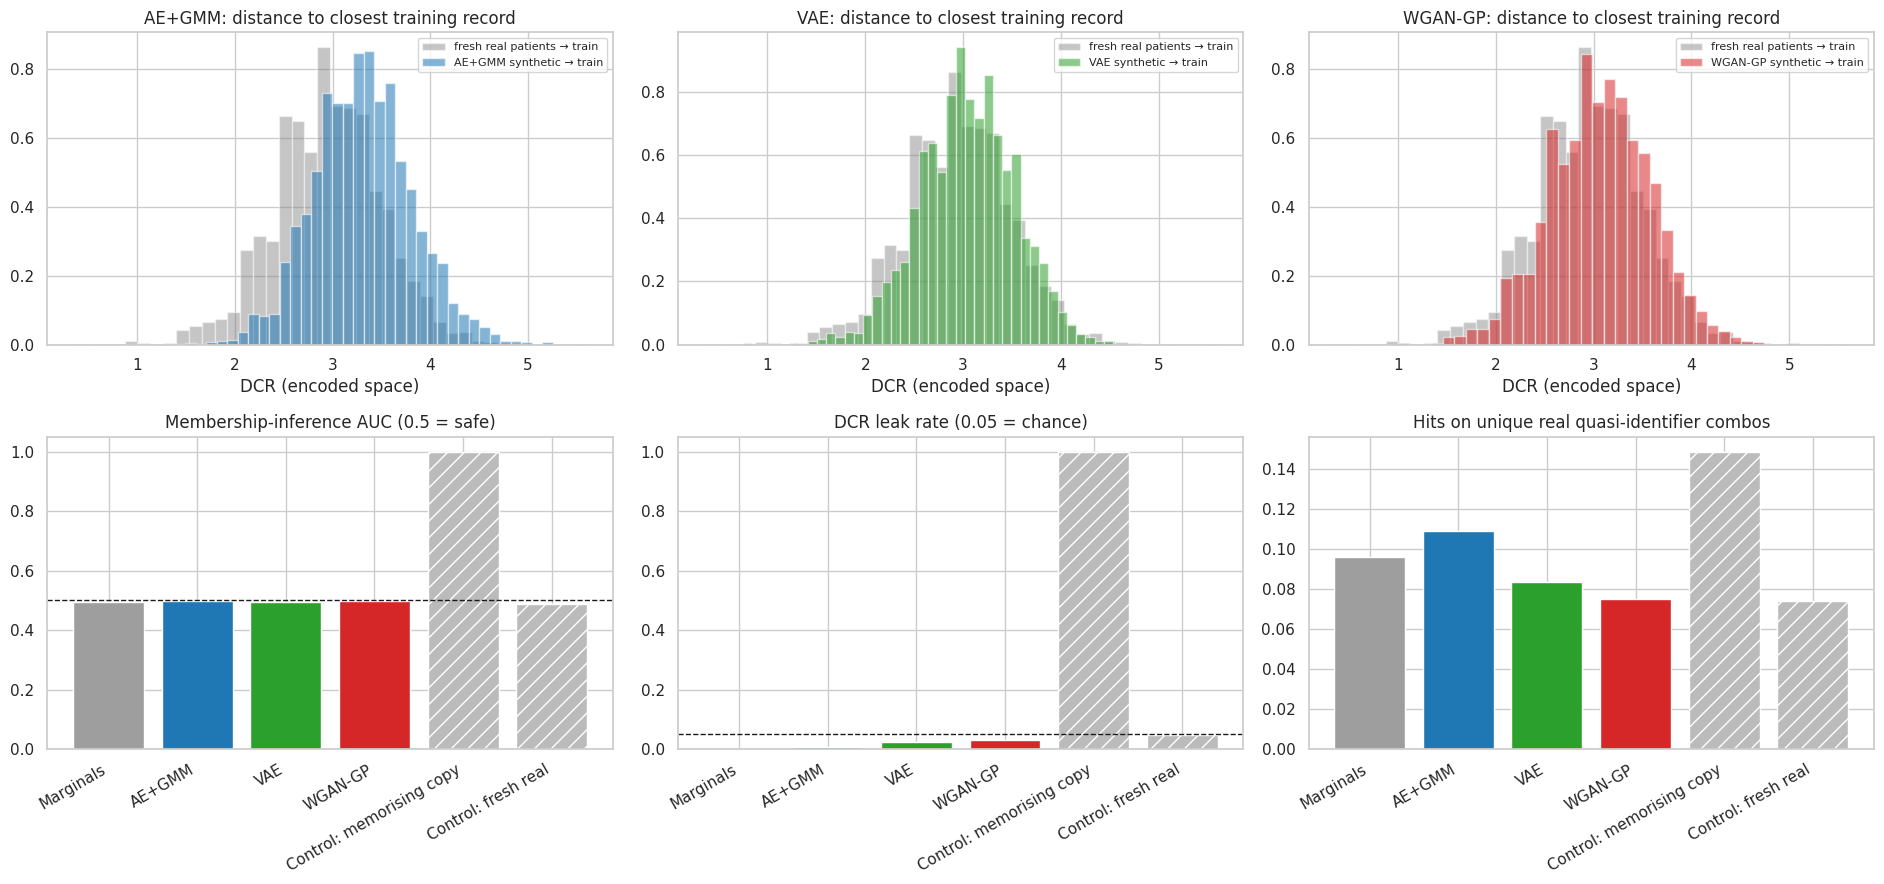

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(19, 9))
for a, m in zip(ax[0], MODELS):
    a.hist(priv[m]['dcr_hold'], bins=40, density=True, alpha=.45, color='#7f7f7f', label='fresh real patients → train')
    a.hist(priv[m]['dcr_syn'], bins=40, density=True, alpha=.55, color=PALETTE[m], label=f'{m} synthetic → train')
    a.set_title(f'{m}: distance to closest training record'); a.set_xlabel('DCR (encoded space)'); a.legend(fontsize=8)
names = list(priv.keys()); cols = [PALETTE.get(n, '#bbbbbb') for n in names]
hatch = ['//' if n.startswith('Control') else '' for n in names]
for a, key, ttl, ref in [(ax[1, 0], 'mia_auc', 'Membership-inference AUC (0.5 = safe)', .5),
                         (ax[1, 1], 'leak_rate', 'DCR leak rate (0.05 = chance)', .05)]:
    bars = a.bar(range(len(names)), [priv[n][key] for n in names], color=cols)
    for b, h in zip(bars, hatch): b.set_hatch(h)
    a.axhline(ref, color='k', ls='--', lw=1); a.set_xticks(range(len(names))); a.set_xticklabels(names, rotation=30, ha='right'); a.set_title(ttl)
bars = ax[1, 2].bar(range(len(names)), [priv[n]['qi_hit'] for n in names], color=cols)
for b, h in zip(bars, hatch): b.set_hatch(h)
ax[1, 2].set_xticks(range(len(names))); ax[1, 2].set_xticklabels(names, rotation=30, ha='right'); ax[1, 2].set_title('Hits on unique real quasi-identifier combos')
plt.tight_layout(); save_show(fig, '09_privacy_audit')

## 21 · Clinical subgroup check (novelty #6)
A synthetic table that gets the overall readmission rate right can still be wrong **inside subgroups** (e.g. older patients). We compare the early-readmission rate per **age band**, **race** and **primary diagnosis group**.
`Subgroup score = 1 − (size-weighted mean absolute error of the group rates ÷ overall real rate)`, clipped to [0, 1].

,Marginals,AE+GMM,VAE,WGAN-GP
age,0.865,0.581,0.842,0.729
race,0.972,0.624,0.846,0.723
diag_1,0.902,0.575,0.845,0.719
mean,0.913,0.594,0.844,0.724


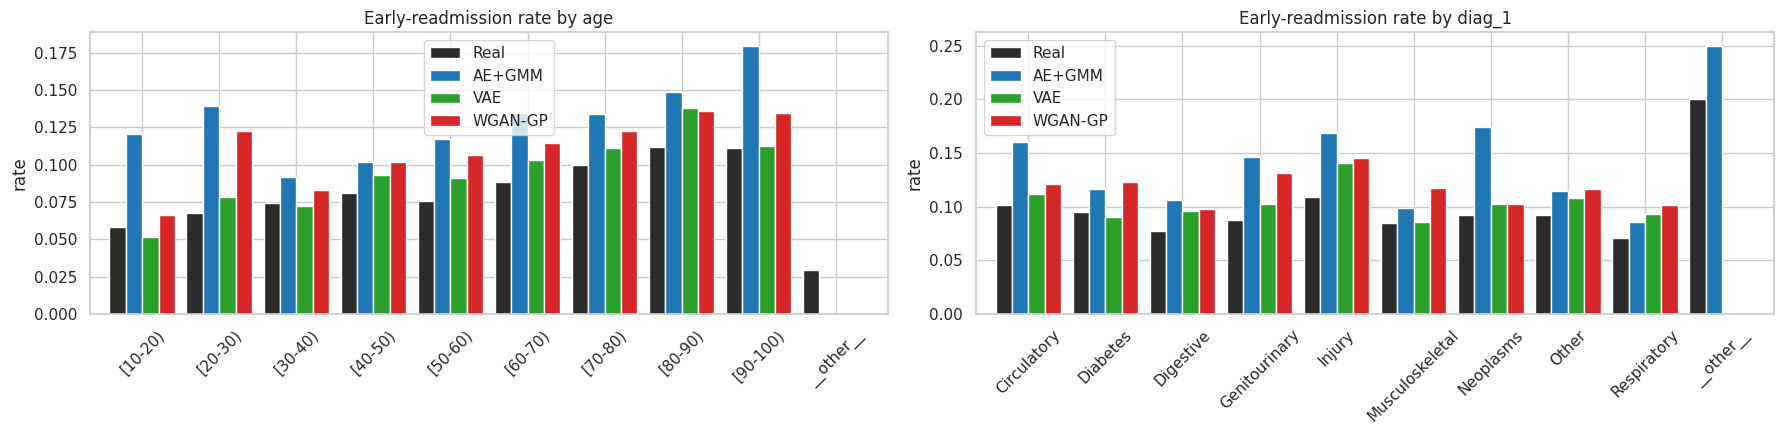

In [ ]:
def group_rates(d, col): return d.groupby(col)[TARGET].apply(lambda s: (s == '1').mean())

def subgroup_score(real, syn, col):
    r = group_rates(real, col); s = group_rates(syn, col).reindex(r.index).fillna(0)
    w = real[col].value_counts(normalize=True).reindex(r.index)
    mae = float((w * (r - s).abs()).sum()); overall = (real[TARGET] == '1').mean()
    return max(0.0, 1 - mae / overall)

SUB_COLS = [c for c in ['age', 'race', 'diag_1'] if c in enc.cat_cols]
sub_tbl = pd.DataFrame({k: {c: subgroup_score(real_train, synth[k], c) for c in SUB_COLS} for k in SOURCES})
sub_tbl.loc['mean'] = sub_tbl.mean()
display(sub_tbl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(18, 4.5))
for a, c in zip(ax, [x for x in ['age', 'diag_1'] if x in SUB_COLS]):
    rr = pd.DataFrame({'Real': group_rates(real_train, c), **{m: group_rates(synth[m], c) for m in MODELS}}).fillna(0)
    rr.plot.bar(ax=a, color=[PALETTE[x] for x in rr.columns], width=.85)
    a.set_title(f'Early-readmission rate by {c}'); a.set_ylabel('rate'); a.set_xlabel(''); a.tick_params(axis='x', rotation=45)
plt.tight_layout(); save_show(fig, '10_subgroup_rates')

## 22 · Where do the synthetic patients live? (PCA view)
A PCA of the encoded space fitted on **real** patients; synthetic points are projected onto it. Good generators overlap the real cloud and cover the same area (no collapse onto a small region).

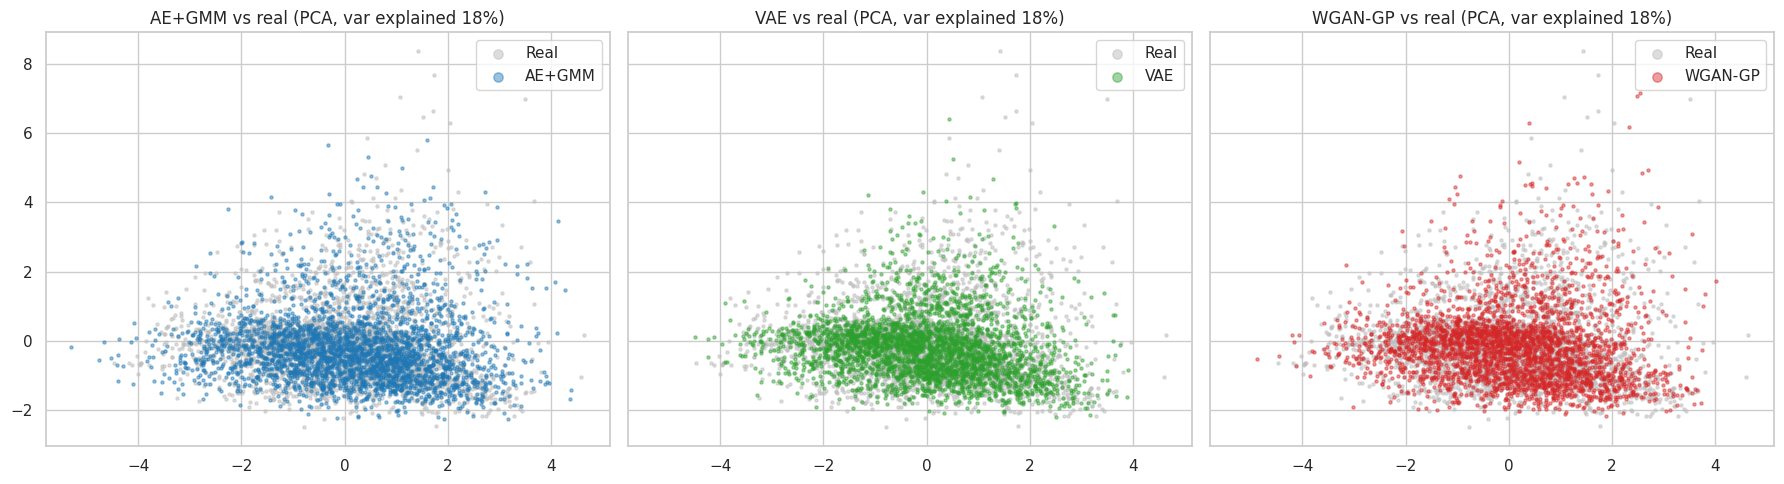

In [ ]:
rs = np.random.default_rng(SEED)
pca = PCA(2, random_state=SEED).fit(X_train[rs.choice(len(X_train), min(6000, len(X_train)), replace=False)])
Pr = pca.transform(X_train[rs.choice(len(X_train), min(3000, len(X_train)), replace=False)])
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for a, m in zip(axes, MODELS):
    Ps = pca.transform(Xsyn_enc[m][rs.choice(len(Xsyn_enc[m]), min(3000, len(Xsyn_enc[m])), replace=False)])
    a.scatter(Pr[:, 0], Pr[:, 1], s=5, color='#bdbdbd', alpha=.5, label='Real')
    a.scatter(Ps[:, 0], Ps[:, 1], s=5, color=PALETTE[m], alpha=.45, label=m)
    a.set_title(f'{m} vs real (PCA, var explained {pca.explained_variance_ratio_.sum():.0%})'); a.legend(markerscale=3)
plt.tight_layout(); save_show(fig, '11_pca_overlay')

## 23 · β-VAE privacy–utility frontier (novelty #2)
In a VAE, **β weights the KL term**: a larger β forces the latent space closer to N(0, I) (smoother, less memorisation, but blurrier data); a smaller β gives sharper reconstructions (higher fidelity, more memorisation risk). We train a VAE for each β, generate a synthetic table and measure **fidelity, utility and membership-leakage** – turning β into an explicit, explainable privacy dial.
(Utility here is the mean skill retention of Logistic Regression and HistGB – two classifiers, so one volatile model cannot dominate – and uses shorter training than the main run to keep the sweep fast.)

β=0.1:   0%|          | 0/25 [00:00<?, ?it/s]

β=0.5:   0%|          | 0/25 [00:00<?, ?it/s]

β=1.0:   0%|          | 0/25 [00:00<?, ?it/s]

β=2.0:   0%|          | 0/25 [00:00<?, ?it/s]

β=4.0:   0%|          | 0/25 [00:00<?, ?it/s]

,beta,fidelity,utility,mia_auc,leak_rate
0,0.1,0.917,0.451,0.493,0.002
1,0.5,0.967,0.793,0.494,0.023
2,1.0,0.973,0.742,0.500,0.024
3,2.0,0.973,0.548,0.493,0.009
4,4.0,0.970,0.208,0.494,0.001


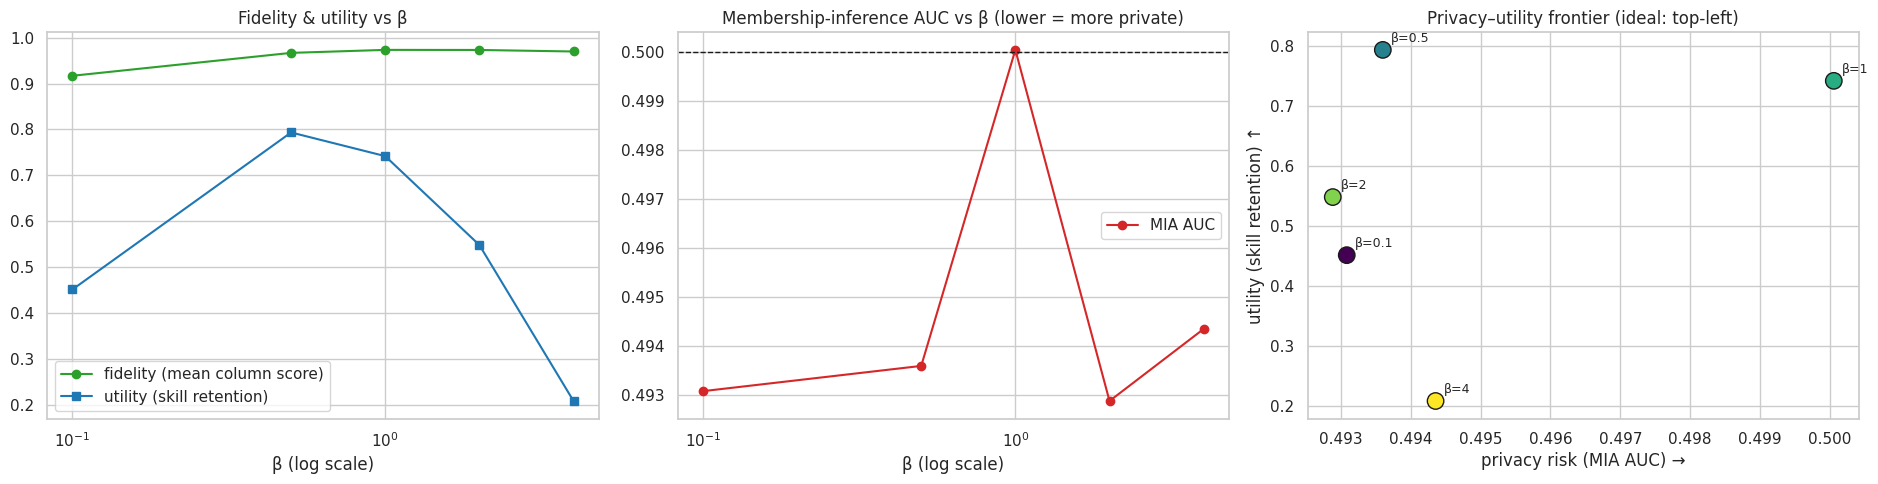

In [ ]:
sweep = []
for b in CFG['beta_grid']:
    m = VAE(enc.dim, CFG['latent_dim']).to(DEVICE)
    train_vae(m, X_train_t, CFG['sweep_epochs'], CFG['lr'], CFG['batch_size'], b, CFG['kl_anneal_frac'], f'β={b}')
    res = recon_residual_std(m, X_train_t, 'vae')
    syn = generate_vae(m, N_SYN, res, CFG['latent_dim']); Xs = enc.transform(syn)
    r_ = fit_eval(*enc.split_xy(Xs), which=['LogReg', 'HistGB'])
    u = np.mean([min(1.5, max(0, r_[c]['auc'] - .5) / denom[c]) for c in r_])
    pa = privacy_audit(X_train, X_test, Xs, CFG['privacy_n'])
    sweep.append(dict(beta=b, fidelity=column_scores(real_train, syn)['score'].mean(),
                      utility=u,
                      mia_auc=pa['mia_auc'], leak_rate=pa['leak_rate']))
sweep = pd.DataFrame(sweep); display(sweep.round(3))

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].plot(sweep.beta, sweep.fidelity, 'o-', color='#2ca02c', label='fidelity (mean column score)')
ax[0].plot(sweep.beta, sweep.utility.clip(upper=1.2), 's-', color='#1f77b4', label='utility (skill retention)')
ax[0].set_xscale('log'); ax[0].set_xlabel('β (log scale)'); ax[0].set_title('Fidelity & utility vs β'); ax[0].legend()
ax[1].plot(sweep.beta, sweep.mia_auc, 'o-', color='#d62728', label='MIA AUC'); ax[1].axhline(.5, color='k', ls='--', lw=1)
ax[1].set_xscale('log'); ax[1].set_xlabel('β (log scale)'); ax[1].set_title('Membership-inference AUC vs β (lower = more private)'); ax[1].legend()
sc = ax[2].scatter(sweep.mia_auc, sweep.utility.clip(upper=1.2), c=np.log10(sweep.beta), cmap='viridis', s=140, edgecolor='k')
for _, r in sweep.iterrows(): ax[2].annotate(f'β={r.beta:g}', (r.mia_auc, min(r.utility, 1.2)), textcoords='offset points', xytext=(6, 6), fontsize=9)
ax[2].set_xlabel('privacy risk (MIA AUC) →'); ax[2].set_ylabel('utility (skill retention) ↑'); ax[2].set_title('Privacy–utility frontier (ideal: top-left)')
plt.tight_layout(); save_show(fig, '12_beta_vae_frontier')

## 24 · Unified scorecard
Every metric is mapped to [0, 1] (higher = better) and grouped into the three pillars:

| Pillar | Components |
|---|---|
| **Fidelity** | column shapes · relationship preservation · subgroup preservation |
| **Utility** | mean TSTR skill retention (capped at 1) |
| **Privacy** | `1 − 2·max(0, MIA-AUC − 0.5)` · `min(1, ref / leak-rate)` where *ref* = leak rate of the fresh-real control (≥ 5 %), i.e. the natural noise level |

**Composite = weighted mean of the three pillars** (equal weights by default – change `W` to reflect your priorities, e.g. weight privacy higher for a healthcare release). The independent-marginals baseline is shown for reference but is **not** ranked.

In [ ]:
W = dict(fidelity=1 / 3, utility=1 / 3, privacy=1 / 3)

def pillar_row(k):
    col, rel, sub = col_scores[k]['score'].mean(), assoc_score[k], sub_tbl.loc['mean', k]
    ut = min(1.0, skill.loc[k, 'mean'])
    p_mia = 1 - 2 * max(0.0, priv[k]['mia_auc'] - .5)
    ref = max(.05, priv['Control: fresh real']['leak_rate'])        # leak rate of genuinely fresh real patients = natural noise level
    p_dcr = min(1.0, ref / max(priv[k]['leak_rate'], 1e-9))
    return dict(**{'Column shapes': col, 'Relationships': rel, 'Subgroups': sub, 'Utility': ut,
                   'Privacy (MIA)': p_mia, 'Privacy (DCR)': p_dcr})

score = pd.DataFrame({k: pillar_row(k) for k in SOURCES}).T
score['Fidelity'] = score[['Column shapes', 'Relationships', 'Subgroups']].mean(1)
score['Privacy'] = score[['Privacy (MIA)', 'Privacy (DCR)']].mean(1)
score['Composite'] = W['fidelity'] * score['Fidelity'] + W['utility'] * score['Utility'] + W['privacy'] * score['Privacy']
score['Train time (s)'] = pd.Series(train_time)
score.to_csv(OUT / 'scorecard.csv')
display(score.round(3).style.background_gradient(cmap='RdYlGn', subset=['Fidelity', 'Utility', 'Privacy', 'Composite'], vmin=0, vmax=1))

,Column shapes,Relationships,Subgroups,Utility,Privacy (MIA),Privacy (DCR),Fidelity,Privacy,Composite,Train time (s)
Marginals,0.997000,0.061000,0.913000,0.025000,1.000000,1.000000,0.657000,1.000000,0.561000,nan
AE+GMM,0.940000,0.809000,0.594000,0.555000,1.000000,1.000000,0.781000,1.000000,0.779000,53.368000
VAE,0.972000,0.834000,0.844000,0.758000,1.000000,1.000000,0.883000,1.000000,0.880000,27.787000
WGAN-GP,0.980000,0.895000,0.724000,0.776000,1.000000,1.000000,0.866000,1.000000,0.881000,131.822000


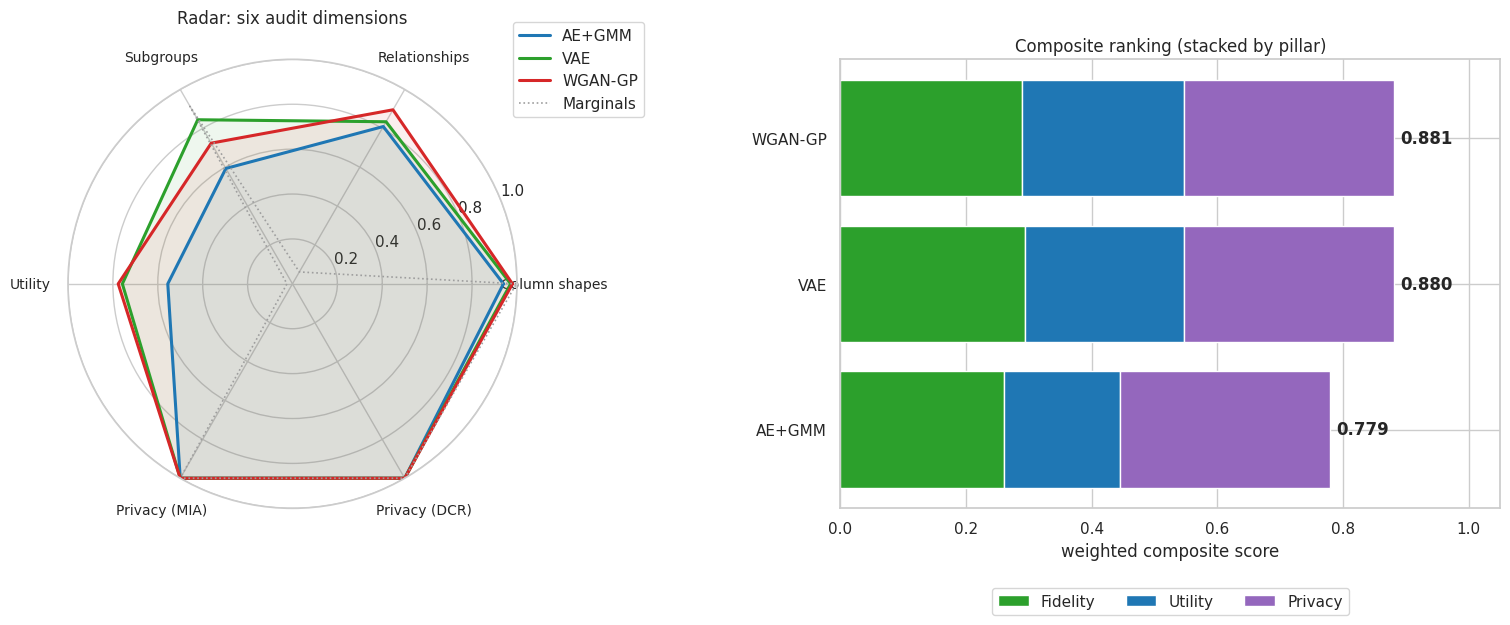

In [ ]:
axes_names = ['Column shapes', 'Relationships', 'Subgroups', 'Utility', 'Privacy (MIA)', 'Privacy (DCR)']
ang = np.linspace(0, 2 * np.pi, len(axes_names), endpoint=False).tolist(); ang += ang[:1]
fig = plt.figure(figsize=(16, 6.5))
ax = fig.add_subplot(1, 2, 1, polar=True)
for k in MODELS + ['Marginals']:
    v = score.loc[k, axes_names].tolist(); v += v[:1]
    ax.plot(ang, v, color=PALETTE[k], lw=2.2 if k != 'Marginals' else 1.2, ls='-' if k != 'Marginals' else ':', label=k)
    if k != 'Marginals': ax.fill(ang, v, color=PALETTE[k], alpha=.08)
ax.set_xticks(ang[:-1]); ax.set_xticklabels(axes_names, fontsize=10); ax.tick_params(axis='x', pad=14); ax.set_ylim(0, 1); ax.set_title('Radar: six audit dimensions', pad=26)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax2 = fig.add_subplot(1, 2, 2)
ranked = score.loc[MODELS].sort_values('Composite', ascending=False)
bottom = np.zeros(len(ranked))
for pillar, colr in [('Fidelity', '#2ca02c'), ('Utility', '#1f77b4'), ('Privacy', '#9467bd')]:
    val = ranked[pillar] * W[pillar.lower()]
    ax2.barh(ranked.index, val, left=bottom, color=colr, label=pillar); bottom += val.values
for i, (n, c) in enumerate(zip(ranked.index, ranked['Composite'])): ax2.text(c + .01, i, f'{c:.3f}', va='center', fontweight='bold')
ax2.set_xlim(0, 1.05); ax2.invert_yaxis(); ax2.set_xlabel('weighted composite score'); ax2.set_title('Composite ranking (stacked by pillar)'); ax2.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=3)
plt.tight_layout(); save_show(fig, '13_scorecard_radar_ranking')

## 25 · Results summary (auto-generated from this run)
The text below is built from the numbers above, so it always matches the current run.

In [ ]:
best = score.loc[MODELS].sort_values('Composite', ascending=False)
top = best.index[0]
print(f'Best overall (composite {best.Composite.iloc[0]:.3f}): {top}\n')
for pillar in ['Fidelity', 'Utility', 'Privacy']:
    print(f'  • Best {pillar:<8}: {score.loc[MODELS, pillar].idxmax():<8} ({score.loc[MODELS, pillar].max():.3f})')
print(f'  • Fastest to train: {score.loc[MODELS, "Train time (s)"].idxmin()} ({score.loc[MODELS, "Train time (s)"].min():.0f}s)')
best_skill, floor_skill = skill.loc[MODELS, 'mean'].max(), skill.loc['Marginals', 'mean']
print()
if max(trtr_auc.values()) - .5 < 0.03:
    print('Utility: the real-data model barely beats chance in this run, so utility ratios are not meaningful - use more rows / epochs.')
elif best_skill > floor_skill + 0.05:
    print(f'Utility: the best synthetic model retains {best_skill:.0%} of the real model\'s above-chance skill vs {floor_skill:.0%} for the '
          f'independent-marginals floor - the generator captures predictive structure beyond column-wise statistics.')
else:
    print(f'Utility: the best synthetic model retains {best_skill:.0%} vs {floor_skill:.0%} for the marginals floor - generators do not clearly beat the floor yet; train longer or enlarge the models.')
best_rel = max(assoc_score[m] for m in MODELS)
print(f'Relationships: best generator reproduces {best_rel:.0%} of real dependency strength vs {assoc_score["Marginals"]:.0%} for the marginals baseline'
      + (' - relationships are being learned.' if best_rel > assoc_score['Marginals'] + .1 else ' - gap to the baseline is small; inspect the association heatmaps.'))
print(f'Privacy audit calibration: memorising-copy control MIA-AUC = {priv["Control: memorising copy"]["mia_auc"]:.2f} '
      f'(flagged), fresh-real control = {priv["Control: fresh real"]["mia_auc"]:.2f} (clean) → the audit can detect leakage.')
worst_leak = max(MODELS, key=lambda m: priv[m]['mia_auc'])
print(f'Highest membership-inference exposure among models: {worst_leak} (AUC {priv[worst_leak]["mia_auc"]:.3f}); exact-match rate ≤ {max(priv[m]["exact_match"] for m in MODELS):.3%}.')

Best overall (composite 0.881): WGAN-GP

  • Best Fidelity: VAE      (0.883)
  • Best Utility : WGAN-GP  (0.776)
  • Best Privacy : AE+GMM   (1.000)
  • Fastest to train: VAE (28s)

Utility: the best synthetic model retains 78% of the real model's above-chance skill vs 2% for the independent-marginals floor - the generator captures predictive structure beyond column-wise statistics.
Relationships: best generator reproduces 90% of real dependency strength vs 6% for the marginals baseline - relationships are being learned.
Privacy audit calibration: memorising-copy control MIA-AUC = 1.00 (flagged), fresh-real control = 0.49 (clean) → the audit can detect leakage.
Highest membership-inference exposure among models: WGAN-GP (AUC 0.498); exact-match rate ≤ 0.000%.


### 25.1 · Export artifacts for the Streamlit app (deployment)
The companion Streamlit app (`app.py`) does **not** retrain anything on startup and does **not** contain any real patient rows. This cell exports exactly what it needs:

| File | Purpose |
|---|---|
| `encoder.json` | column layout, category lists, scaling statistics |
| `ae.pt`, `vae.pt`, `gan.pt` | trained generators (weights only; the AE also stores its latent-GMM parameters) |
| `reference.json` | **aggregate** statistics of the real training table (histograms, category proportions, association matrix, subgroup rates) used to score generated data |
| `*.csv` + `figures/` | the comparison tables and plots from this notebook |
| `meta.json` | run settings and timings |

Run it, then copy the `app_artifacts` folder (or unzip `app_artifacts.zip`) into the app's `artifacts/` directory.

In [ ]:
import json, shutil
ART = OUT / 'app_artifacts'
(ART / 'figures').mkdir(parents=True, exist_ok=True)

# 1 · encoder (plain JSON, no pickled classes)
enc_dict = dict(num_cols=enc.num_cols, cat_cols=enc.cat_cols, min_freq=enc.min_freq,
                num_min=enc.num_min, num_max=enc.num_max,
                scale_mean=enc.scaler.mean_.tolist(), scale_std=enc.scaler.scale_.tolist(),
                cats=enc.cats, fallback=enc.fallback)
(ART / 'encoder.json').write_text(json.dumps(enc_dict))

# 2 · generators (tensors only, so they load with torch.load(weights_only=True))
cpu = lambda sd: {k: v.detach().cpu() for k, v in sd.items()}
torch.save(dict(state=cpu(ae.state_dict()), res_std=ae_res.cpu(),
                gmm_w=torch.tensor(gmm.weights_), gmm_mu=torch.tensor(gmm.means_),
                gmm_cov=torch.tensor(gmm.covariances_)), ART / 'ae.pt')
torch.save(dict(state=cpu(vae.state_dict()), res_std=vae_res.cpu()), ART / 'vae.pt')
torch.save(dict(state=cpu(G.state_dict())), ART / 'gan.pt')

# 3 · aggregate reference statistics (no patient-level rows)
ref = dict(
    n_train=int(len(real_train)), target_rate=float((real_train[TARGET] == '1').mean()),
    num_pmf={c: {str(k): float(v) for k, v in real_train[c].value_counts(normalize=True).items()} for c in enc.num_cols},
    cat_prop={c: {str(k): float(v) for k, v in real_train[c].value_counts(normalize=True).items()} for c in enc.cat_cols},
    assoc_cols=list(A['Real'].columns), assoc=A['Real'].round(5).values.tolist(),
    subgroup_rates={c: {str(k): float(v) for k, v in group_rates(real_train, c).items()} for c in SUB_COLS},
    subgroup_share={c: {str(k): float(v) for k, v in real_train[c].value_counts(normalize=True).items()} for c in SUB_COLS})
(ART / 'reference.json').write_text(json.dumps(ref))

# 4 · result tables used by the "Compare models" page
score.to_csv(ART / 'scorecard.csv');         util_df.to_csv(ART / 'utility.csv', index=False)
skill.to_csv(ART / 'skill.csv');             priv_tbl.to_csv(ART / 'privacy.csv')
sub_tbl.to_csv(ART / 'subgroups.csv');       sweep.to_csv(ART / 'beta_sweep.csv', index=False)
fid_tbl.to_csv(ART / 'column_fidelity.csv'); top_tbl.to_csv(ART / 'top_relationships.csv')

# 5 · figures + run metadata
for p in FIG.glob('*.png'): shutil.copy(p, ART / 'figures' / p.name)
meta = dict(dataset='UCI Diabetes 130-US Hospitals (1999-2008), dataset id 296',
            n_train=int(len(real_train)), n_test=int(len(real_test)), encoded_width=int(enc.dim),
            positive_rate=float((real_train[TARGET] == '1').mean()),
            latent_dim=int(CFG['latent_dim']), gan_z_dim=int(CFG['gan_z_dim']),
            cfg={k: v for k, v in CFG.items()}, fast_dev=bool(FAST_DEV),
            train_time={k: float(v) for k, v in train_time.items()}, pillar_weights=W,
            models=MODELS, sources=SOURCES, torch=torch.__version__,
            exported=time.strftime('%Y-%m-%d %H:%M:%S'))
(ART / 'meta.json').write_text(json.dumps(meta, indent=1))

shutil.make_archive(str(OUT / 'app_artifacts'), 'zip', ART)
size_mb = sum(f.stat().st_size for f in ART.rglob('*') if f.is_file()) / 1e6
print(f'Exported {len(list(ART.rglob("*.*")))} files ({size_mb:.1f} MB) -> {ART}  and  {OUT / "app_artifacts.zip"}')
if FAST_DEV: print('NOTE: FAST_DEV was on - export a full run (FAST_DEV = False) before deploying.')
try:                                   # Colab: download straight to your computer
    from google.colab import files; files.download(str(OUT / 'app_artifacts.zip'))
except Exception:
    pass

Exported 27 files (4.5 MB) -> outputs/app_artifacts  and  outputs/app_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 26 · Limitations (state these before the examiner does)
* **Empirical privacy only.** DCR/MIA/exact-match are *audits*; none of the models carries a formal differential-privacy guarantee. A natural extension is DP-SGD (e.g. Opacus) for the VAE/GAN.
* **Public, already de-identified proxy data.** The dataset stands in for a restricted hospital EHR; in a real deployment the same pipeline would run inside the hospital and only the synthetic table would leave.
* **Dated, US-specific cohort** (1999–2008). Prescribing patterns have changed, so the data is a methodological testbed, not a basis for current clinical claims.
* **Modest downstream ceiling.** Early readmission is hard to predict; absolute AUCs are low, so conclusions rely on *relative* skill retention.
* **Representation choices matter.** Merging rare categories, grouping ICD-9 codes and subsampling reduce dimensionality (and risk) but also limit what the generators can reproduce.
* **Single dataset, single seed.** Averaging over several seeds and a second dataset would tighten the conclusions.
* **Not a clinical tool.** Synthetic records must not be used for patient care.

## 27 · Future work
DP-SGD training and ε–utility curves · conditional GAN / TVAE-style mode-specific normalisation · diffusion-based tabular generators · a second dataset (e.g. Heart Failure Clinical Records) · attribute-inference attacks and formal k-anonymity checks.

---
# 28 · Defence notes (dataset, design decisions, likely questions)

## 28.1 Dataset in one glance
| Item | Detail |
|---|---|
| Name | Diabetes 130-US Hospitals for Years 1999–2008 |
| Host | UCI Machine Learning Repository, dataset ID **296** (`archive.ics.uci.edu/dataset/296`) — donated 2014 |
| Origin | Health Facts database; 130 US hospitals and integrated delivery networks; 10 years of care |
| Size | **101,766 encounters × 50 attributes** (≈18 MB CSV) + `IDS_mapping.csv` |
| Inclusion rule | inpatient, diabetes diagnosed, stay 1–14 days, lab tests performed, medications given |
| Content | demographics (race, gender, age band), admission/discharge type, payer, admitting specialty, 3 diagnosis codes, lab flags (HbA1c, glucose), ~23 drug columns, visit counts, readmission status |
| Label | `readmitted` ∈ {NO, >30, <30} → we use `<30` (**early readmission**) |
| Paper | Strack et al., *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*, BioMed Research International, 2014 |
| Access | free download, no credentialing (check the UCI page for the current licence terms) |

**Why this dataset is defensible:** real clinical data (not toy), large enough for deep generators, mixed numeric/categorical/ordinal columns, a clear clinical task with natural class imbalance, rich in quasi-identifiers (so the privacy argument is concrete), peer-reviewed provenance, and widely used as a benchmark (including in fairness research).

## 28.2 The 60-second pitch
> Hospitals cannot freely share patient records, which blocks research and teaching. We built three deep generators – an Autoencoder (made generative with a latent GMM), a β-VAE and a WGAN-GP – on 100k-encounter diabetes data, and judged them on three pillars instead of one: **fidelity** (histograms *and* feature relationships), **utility** (train-on-synthetic, test-on-real readmission prediction) and **privacy** (distance-to-closest-record, exact matches, quasi-identifier hits and a membership-inference attack, calibrated with a memorising control). We also show how the VAE's β acts as a privacy–utility dial.

## 28.3 Likely viva questions and answers
**Q1. Why these three models?**  They are the syllabus generative families – deterministic autoencoder, probabilistic latent-variable model (VAE) and adversarial model (GAN) – and they trade off differently: AE/VAE train fast and are stable, the GAN can give sharper samples but is harder to train.

**Q2. A plain autoencoder can't generate data. How did you use it?**  We fit a Gaussian Mixture on the latent codes of the training data and decode samples from the mixture – a simple way to give the AE a sampling distribution.

**Q3. Why not use SDV / CTGAN directly?**  The goal of the lab is to implement and understand the generative architectures. CTGAN/TVAE are the reference designs; our WGAN-GP with Gumbel-softmax and our KL-annealed β-VAE follow the same ideas (Xu et al., 2019) and are compared with a transparent audit.

**Q4. How do you handle mixed data types?**  Numeric counts are log-transformed and standardised; categorical columns are one-hot encoded; the decoders output Gaussian (numeric) and categorical (softmax) parameters and the loss is MSE + cross-entropy. For the GAN, categorical outputs pass through Gumbel-softmax.

**Q5. What is posterior collapse and how did you avoid it?**  The VAE ignores its latent code and the KL goes to zero. KL annealing (β ramps from 0) and monitoring the KL curve address it (Bowman et al., 2016).

**Q6. Why WGAN-GP instead of a vanilla GAN?**  The Wasserstein loss with gradient penalty gives smoother gradients and a loss that tracks quality, which reduces mode collapse and training instability (Arjovsky et al., 2017; Gulrajani et al., 2017).

**Q7. How is utility measured?**  TSTR: train a classifier on synthetic data, test on a *real* hold-out, compare against TRTR. We report ROC-AUC, PR-AUC and F1 for three classifiers and normalise to *skill retention* because an AUC of 0.5 is already "free".

**Q8. Why is the independent-marginals baseline in the results?**  It matches every histogram but breaks every relationship. If a metric did not punish it, the metric would be useless. It also gives the utility floor.

**Q9. How do you know the privacy audit works?**  We ran two controls through it: a memorising generator (copy of training rows) is flagged with MIA-AUC near 1 and a large leak rate; fresh real patients score ≈0.5 / ≈5 %.

**Q10. Is the synthetic data "private"?**  Not formally – we provide empirical audits, not a differential-privacy guarantee. We say so explicitly and list DP-SGD as future work. Merging rare categories and removing identifiers reduces, but does not eliminate, risk.

**Q11. Why only the first encounter per patient?**  Multiple encounters from one person would be correlated, could leak across train/test, and would make membership-inference results meaningless.

**Q12. Why exclude expired/hospice discharges?**  Those patients cannot be readmitted; keeping them would label genuinely un-readmittable patients as "no readmission".

**Q13. The AUC is low – is the project weak?**  30-day readmission is a notoriously hard task; the contribution is the *relative* comparison (how much of the real model's skill each synthetic table keeps) and the privacy audit, not a state-of-the-art predictor.

**Q14. What is the novelty?**  (1) generative AE via latent GMM, (2) β-VAE privacy–utility frontier, (3) mixed-type relationship-preservation metric, (4) three-pillar scorecard, (5) audit calibration with controls, (6) clinical subgroup check, (7) leakage-safe cohort design.

**Q15. What would you do with more time?**  DP-SGD with ε–utility curves, multiple seeds with confidence intervals, a second dataset, and diffusion-based tabular generators.

## 28.4 References
1. Kingma, D. P., & Welling, M. (2014). *Auto-Encoding Variational Bayes.* ICLR.
2. Goodfellow, I., et al. (2014). *Generative Adversarial Nets.* NeurIPS.
3. Arjovsky, M., Chintala, S., & Bottou, L. (2017). *Wasserstein GAN.* ICML.
4. Gulrajani, I., et al. (2017). *Improved Training of Wasserstein GANs.* NeurIPS.
5. Higgins, I., et al. (2017). *β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework.* ICLR.
6. Bowman, S. R., et al. (2016). *Generating Sentences from a Continuous Space.* CoNLL.
7. Xu, L., et al. (2019). *Modeling Tabular Data using Conditional GAN.* NeurIPS.
8. Choi, E., et al. (2017). *Generating Multi-label Discrete Patient Records using Generative Adversarial Networks.* MLHC.
9. Esteban, C., Hyland, S. L., & Rätsch, G. (2017). *Real-valued (Medical) Time Series Generation with Recurrent Conditional GANs.* arXiv:1706.02633 (introduces TSTR).
10. Shokri, R., et al. (2017). *Membership Inference Attacks Against Machine Learning Models.* IEEE S&P.
11. Strack, B., et al. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International, 2014.

_(Double-check reference formatting against your department's required citation style before submission.)_